# 01 · EDA tuần 2 đến tuần 4



In [1]:
# ===== Thiết lập chung cho cả ba phần =====
import os, sys, time, textwrap, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 170)

SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)
N_BOOT = 300                   # số lần bootstrap (phần 3)
CUTOFF_DAY = 28                # tham số; khớp config.cutoff_day của Trường
WINDOW = f"ngày 0–{CUTOFF_DAY - 1}"
WINDOWS = [14, 28, 56]         # các cửa sổ so sánh ở phần 3
TOTAL_ENROLMENTS = 32593       # tổng lượt đăng ký (cohort + rút sớm)

CWD = Path.cwd().resolve()
ROOT = CWD.parent if CWD.name == "notebooks" else CWD
RAW_DIR = Path(os.environ.get("OULAD_RAW_DIR", ROOT / "data" / "raw"))
RESULTS_DIR = Path(os.environ.get("OULAD_RESULTS_DIR", ROOT / "results"))
PROC_DIR = Path(os.environ.get("OULAD_PROC_DIR", ROOT / "data" / "processed"))
FEATURE_PATH = Path(os.environ.get("OULAD_FEATURE_PATH", PROC_DIR / "feature_28d.csv"))
SPLIT_PATH = Path(os.environ.get("OULAD_SPLIT_PATH", PROC_DIR / "split.csv"))
# bộ so sánh độ nhạy (phần 3) trong data/processed/sensitivity/: feature_14d_s/28d_s/56d_s.csv + split_s.csv, cohort cố định (còn đăng ký ở đầu ngày 56)
SENS_DIR = Path(os.environ.get("OULAD_SENS_DIR", PROC_DIR / "sensitivity"))
SENS_SPLIT_PATH = Path(os.environ.get("OULAD_SENS_SPLIT_PATH", SENS_DIR / "split_s.csv"))
EDA_DIR = RESULTS_DIR / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT))

from src.etl.features_demographic import EDUCATION_ORDER, AGE_ORDER, KEYS, _imd_to_ordinal

# ---- kiểu dáng: nền sáng, mực trung tính, lưới mờ, mark mảnh; màu theo bảng đã kiểm định ----
SURFACE, INK, INK2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898883", "#e4e3de"
BLUE, ORANGE, BLUE_LIGHT, GREY = "#2a78d6", "#eb6834", "#9ec5f4", "#b8b7b0"
AQUA, YELLOW = "#1baf7a", "#eda100"   # tương phản thấp: luôn kèm ký hiệu hình dạng + chú thích
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "font.size": 10, "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False,
})
FMT_INT = FuncFormatter(lambda x, _: f"{x:,.0f}")
def fmt(n): return f"{int(n):,}".replace(",", ".")

# Phần 1 · EDA tuần 2: phân bố, rút lui theo ngày, cỡ cohort 

In [2]:
# ---- Phần 1: hàm lưu hình và manifest ----
plt.rcParams["axes.titlesize"] = 12
MANIFEST = []
def finish(fig, cid, slug, title, source, n, window, label_used, data):
    # ghi n, nguồn, cửa sổ lên hình; lưu PNG + CSV; ghi vào manifest
    note = "chỉ mô tả toàn bộ dữ liệu, không dùng chọn feature" if label_used else "không dùng nhãn"
    fig.text(0.01, 0.006, f"n = {n:,} · nguồn: {source} · cửa sổ: {window} · {note}",
             fontsize=8, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.035, 1, 1))
    png, csv = EDA_DIR / f"{cid}_{slug}.png", EDA_DIR / f"{cid}_{slug}.csv"
    fig.savefig(png, dpi=150)
    data.to_csv(csv, index=False, encoding="utf-8-sig")
    MANIFEST.append(dict(chart_id=cid, title=title, source=source, n=int(n), window=window,
                         label_used="có (mô tả, toàn bộ)" if label_used else "không",
                         png=png.name, csv=csv.name))
    plt.show()
    print("đã lưu:", png.name, "+", csv.name)

## 1. Đọc dữ liệu cần dùng

In [3]:
NA = ["?", ""]
need = ["studentInfo", "studentRegistration"]
missing_files = [t for t in need if not (RAW_DIR / f"{t}.csv").exists()]
if missing_files:
    raise FileNotFoundError(f"Thiếu file trong {RAW_DIR}: {[t + '.csv' for t in missing_files]}")

student_info = pd.read_csv(RAW_DIR / "studentInfo.csv", na_values=NA, dtype={"id_student": "int32"})
student_reg = pd.read_csv(RAW_DIR / "studentRegistration.csv", na_values=NA, dtype={"id_student": "int32"})

N_ALL = len(student_reg)
print(f"studentInfo={len(student_info):,} | studentRegistration={N_ALL:,}")
assert len(student_info) == N_ALL, "studentInfo và studentRegistration lệch số dòng; xem báo cáo chất lượng"
assert not student_reg.duplicated(KEYS).any() and not student_info.duplicated(KEYS).any()
SUMMARY = {}   # gom số liệu chính để ghi tóm tắt cuối notebook

studentInfo=32,593 | studentRegistration=32,593


## 2. w2_01 · Phân bố `final_result`

Toàn bộ 32.593 lượt đăng ký, theo đúng bảng biểu đồ của kế hoạch. Chỉ để hiểu nhãn, **không** dùng để chọn feature. Lớp dương của `label_withdrawn` là Withdrawn; nhớ rằng mô hình chỉ dự đoán cho người còn học ở ngày 28.

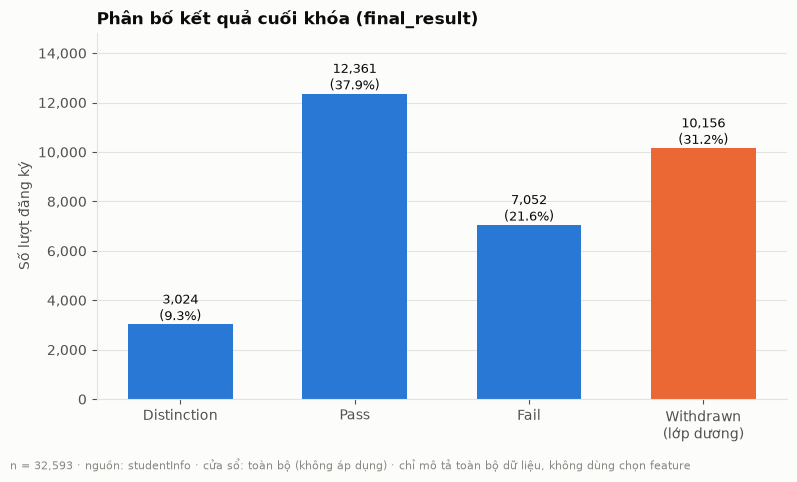

đã lưu: w2_01_final_result.png + w2_01_final_result.csv


có date_unregistration,False,True
final_result == Withdrawn,,
False,22428,9
True,93,10063


Withdrawn nhưng trống date_unregistration: 93 | có date_unregistration nhưng không Withdrawn: 9


In [4]:
order = ["Distinction", "Pass", "Fail", "Withdrawn"]
vc = student_info["final_result"].value_counts()
order += [k for k in vc.index if k not in order]          # giá trị lạ (nếu có) vẫn được vẽ
fr = vc.reindex(order).fillna(0).astype(int)
n1 = int(fr.sum())

fig, ax = plt.subplots(figsize=(8, 4.8))
ax.bar(range(len(fr)), fr.values, width=0.6, color=[ORANGE if k == "Withdrawn" else BLUE for k in fr.index])
for i, v in enumerate(fr.values):
    ax.text(i, v, f"{v:,}\n({v / n1:.1%})", ha="center", va="bottom", fontsize=9, color=INK)
ax.set_xticks(range(len(fr)))
ax.set_xticklabels([k + ("\n(lớp dương)" if k == "Withdrawn" else "") for k in fr.index])
ax.set_ylim(0, fr.max() * 1.2)
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_ylabel("Số lượt đăng ký")
ax.grid(axis="x", visible=False)
ax.set_title("Phân bố kết quả cuối khóa (final_result)")

d1 = pd.DataFrame({"final_result": fr.index, "n": fr.values, "pct": (fr.values / n1).round(4)})
finish(fig, "w2_01", "final_result", "Phân bố final_result", "studentInfo", n1, "toàn bộ (không áp dụng)", True, d1)
SUMMARY["w2_01"] = {k: int(v) for k, v in fr.items()}

# Kiểm tra nhất quán: Withdrawn có khớp với việc có date_unregistration không? (toàn bộ dữ liệu, chỉ để báo Trường)
chk = student_info[KEYS + ["final_result"]].merge(
    student_reg[KEYS + ["date_unregistration"]], on=KEYS, how="left", validate="one_to_one")
ct = pd.crosstab(chk["final_result"].eq("Withdrawn"), chk["date_unregistration"].notna(),
                 rownames=["final_result == Withdrawn"], colnames=["có date_unregistration"])
display(ct)
SUMMARY["wd_without_unreg"] = int(ct.loc[True, False]) if (True in ct.index and False in ct.columns) else 0
SUMMARY["unreg_not_wd"] = int(ct.loc[False, True]) if (False in ct.index and True in ct.columns) else 0
print("Withdrawn nhưng trống date_unregistration:", SUMMARY["wd_without_unreg"],
      "| có date_unregistration nhưng không Withdrawn:", SUMMARY["unreg_not_wd"])

## 3. w2_02 · Số lượt đăng ký rút lui tích lũy theo ngày

Dùng toàn bộ 32.593 lượt đăng ký (checklist: phải ghi rõ). Biểu đồ giải thích vì sao chọn cửa sổ 28 ngày và vì sao cohort bị loại bớt người rút sớm. Cohort = còn đăng ký ở đầu ngày 28 (`date_unregistration` trống hoặc ≥ 28).

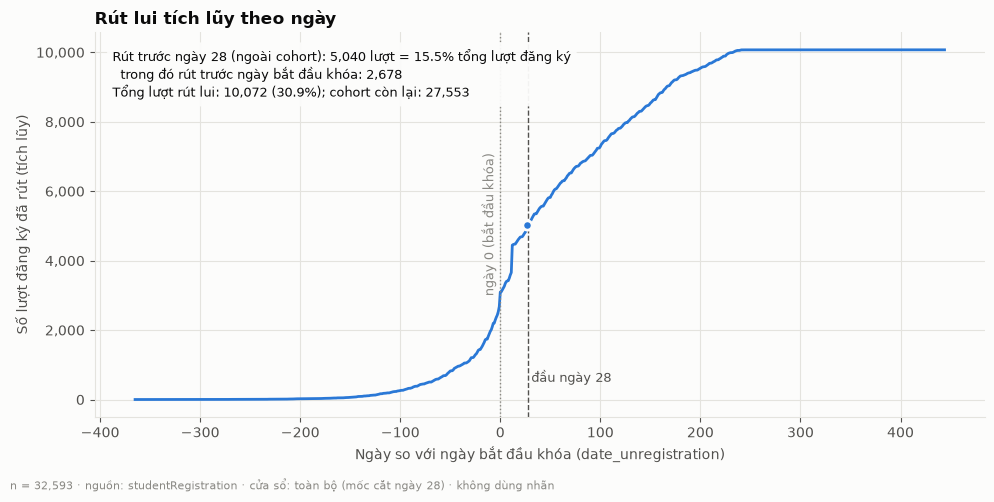

đã lưu: w2_02_withdrawn_cumulative.png + w2_02_withdrawn_cumulative.csv


In [5]:
du = student_reg["date_unregistration"].dropna().astype(int)
by_day = du.value_counts().sort_index()
days = np.arange(by_day.index.min(), by_day.index.max() + 1)
daily = by_day.reindex(days, fill_value=0)
cum = daily.cumsum()

n_wd = int(len(du))
n_early = int((du < CUTOFF_DAY).sum())        # rút trước ngày 28 -> ngoài cohort
n_neg = int((du < 0).sum())                   # rút trước ngày bắt đầu khóa
n_cohort = N_ALL - n_early
cum_at_cut = int(cum.loc[CUTOFF_DAY - 1])     # số đã rút tính đến hết ngày 27
assert cum_at_cut == n_early

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(days, cum.values, color=BLUE, lw=2)
ax.axvline(CUTOFF_DAY, color=INK2, lw=1, ls="--")
ax.axvline(0, color=MUTED, lw=1, ls=":")
ax.scatter([CUTOFF_DAY - 1], [cum_at_cut], s=45, color=BLUE, edgecolor=SURFACE, linewidth=2, zorder=5)
ax.text(CUTOFF_DAY + 3, ax.get_ylim()[1] * 0.04, f"đầu ngày {CUTOFF_DAY}", color=INK2, fontsize=9, va="bottom")
ax.text(-4, 0.5, "ngày 0 (bắt đầu khóa)", color=MUTED, fontsize=9, va="center", ha="right",
        rotation=90, transform=ax.get_xaxis_transform())
ax.text(0.02, 0.96,
        f"Rút trước ngày {CUTOFF_DAY} (ngoài cohort): {n_early:,} lượt = {n_early / N_ALL:.1%} tổng lượt đăng ký\n"
        f"  trong đó rút trước ngày bắt đầu khóa: {n_neg:,}\n"
        f"Tổng lượt rút lui: {n_wd:,} ({n_wd / N_ALL:.1%}); cohort còn lại: {n_cohort:,}",
        transform=ax.transAxes, va="top", fontsize=9.5, color=INK, zorder=10,
        bbox=dict(boxstyle="round,pad=0.4", facecolor=SURFACE, edgecolor="none", alpha=0.95))
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_xlabel("Ngày so với ngày bắt đầu khóa (date_unregistration)")
ax.set_ylabel("Số lượt đăng ký đã rút (tích lũy)")
ax.set_title("Rút lui tích lũy theo ngày")

d2 = pd.DataFrame({"day": days, "n_unregistered": daily.values, "cumulative": cum.values,
                   "cumulative_pct_of_all": (cum.values / N_ALL).round(5)})
finish(fig, "w2_02", "withdrawn_cumulative", "Rút lui tích lũy theo ngày", "studentRegistration",
       N_ALL, f"toàn bộ (mốc cắt ngày {CUTOFF_DAY})", False, d2)
SUMMARY["w2_02"] = dict(n_all=N_ALL, n_withdraw_dates=n_wd, n_early=n_early, n_neg=n_neg, n_cohort=n_cohort)

## 3b. w2_02b · Đỉnh rút lui theo ngày: module/đợt nào đóng góp?

Đường tích lũy ở w2_02 có bước nhảy quanh ngày 0 và quanh ngày 12. Biểu đồ này vẽ **số lượt rút mỗi ngày** (không tích lũy) trong khoảng ngày -30 đến 60 và chỉ ra module/đợt nào chiếm phần lớn ở 3 ngày cao nhất. Nếu một module/đợt chiếm gần hết một đỉnh, đó là mốc riêng của khóa đó (ví dụ hạn hủy đăng ký), không phải hành vi chung. Không dùng nhãn.

,day,n_day,module_presentation,n_mp,share_of_day
0,12,788,FFF 2014J,217,0.275
1,12,788,BBB 2014J,181,0.230
2,12,788,CCC 2014J,135,0.171
3,0,419,BBB 2013J,102,0.243
4,0,419,FFF 2013J,79,0.189
5,0,419,DDD 2013J,41,0.098
6,27,170,BBB 2013B,59,0.347
7,27,170,FFF 2013B,47,0.276
8,27,170,DDD 2013B,34,0.200


Trung vị số lượt rút mỗi ngày trong khoảng -30..60: 45


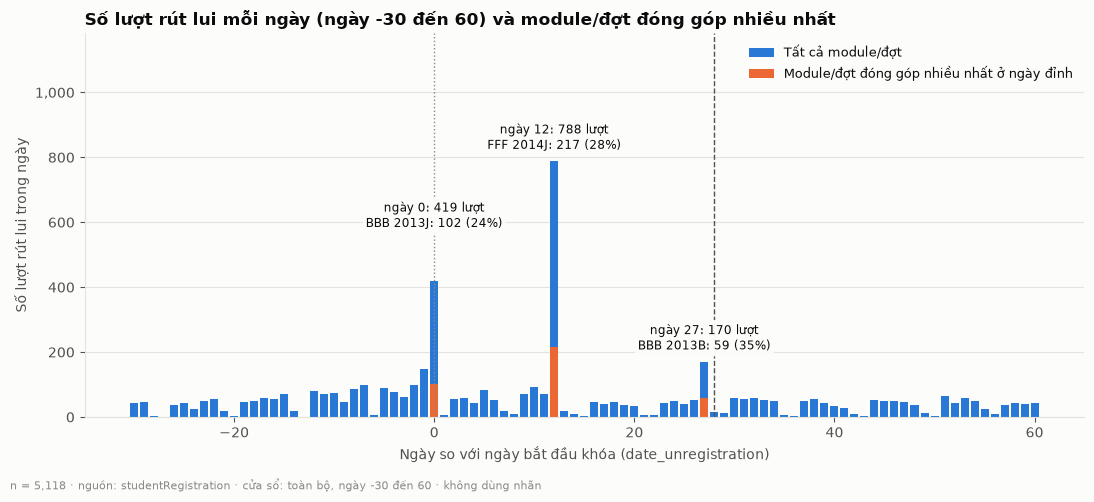

đã lưu: w2_02b_withdrawn_spikes.png + w2_02b_withdrawn_spikes.csv
Ngày 12: 788 lượt; lớn nhất FFF 2014J chiếm 28% -> phân tán qua nhiều khóa
Ngày 0: 419 lượt; lớn nhất BBB 2013J chiếm 24% -> phân tán qua nhiều khóa
Ngày 27: 170 lượt; lớn nhất BBB 2013B chiếm 35% -> phân tán qua nhiều khóa


In [6]:
reg_d = student_reg.dropna(subset=["date_unregistration"]).copy()
reg_d["day"] = reg_d["date_unregistration"].astype(int)
reg_d["mp"] = reg_d["code_module"].astype(str) + " " + reg_d["code_presentation"].astype(str)

LO, HI = -30, 60
win = reg_d[(reg_d["day"] >= LO) & (reg_d["day"] <= HI)]
daily_w = win.groupby("day").size().reindex(range(LO, HI + 1), fill_value=0)
top_days = daily_w.sort_values(ascending=False).head(3).index.tolist()

rows_sp = []
for d in top_days:
    vc = win.loc[win["day"] == d, "mp"].value_counts()
    for mp, c in vc.head(3).items():
        rows_sp.append(dict(day=int(d), n_day=int(daily_w[d]), module_presentation=mp,
                            n_mp=int(c), share_of_day=round(c / daily_w[d], 3)))
spikes = pd.DataFrame(rows_sp)
display(spikes)
print(f"Trung vị số lượt rút mỗi ngày trong khoảng {LO}..{HI}: {daily_w.median():.0f}")

fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(daily_w.index, daily_w.values, width=0.8, color=BLUE, label="Tất cả module/đợt")
for k, d in enumerate(top_days):
    first = spikes[spikes["day"] == d].iloc[0]
    if k == 0:
        ax.bar([d], [first["n_mp"]], width=0.8, color=ORANGE, label="Module/đợt đóng góp nhiều nhất ở ngày đỉnh")
    else:
        ax.bar([d], [first["n_mp"]], width=0.8, color=ORANGE)
    if daily_w[d] >= 3 * max(daily_w.median(), 1):          # chỉ gắn nhãn đỉnh vượt rõ mức thường ngày
        ax.annotate(f"ngày {d}: {first['n_day']:,} lượt\n{first['module_presentation']}: {first['n_mp']:,} ({first['share_of_day']:.0%})",
                    (d, daily_w[d]), xytext=(0, 6 + 30 * (k % 2)), textcoords="offset points",
                    ha="center", va="bottom", fontsize=8.5, color=INK, zorder=10,
                    bbox=dict(boxstyle="round,pad=0.25", facecolor=SURFACE, edgecolor="none", alpha=0.95))
ax.axvline(0, color=MUTED, lw=1, ls=":")
ax.axvline(CUTOFF_DAY, color=INK2, lw=1, ls="--")
ax.set_ylim(0, daily_w.max() * 1.5)
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_xlabel("Ngày so với ngày bắt đầu khóa (date_unregistration)")
ax.set_ylabel("Số lượt rút lui trong ngày")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right", fontsize=9)
ax.set_title(f"Số lượt rút lui mỗi ngày (ngày {LO} đến {HI}) và module/đợt đóng góp nhiều nhất")

top_by_day = (win.groupby(["day", "mp"]).size().rename("n_top").reset_index()
                 .sort_values(["day", "n_top"], ascending=[True, False]).drop_duplicates("day")
                 .rename(columns={"mp": "top_module_presentation"}))
d2b = daily_w.rename("n_unregistered").reset_index().merge(top_by_day, on="day", how="left")
finish(fig, "w2_02b", "withdrawn_spikes", "Đỉnh rút lui theo ngày và module/đợt đóng góp", "studentRegistration",
       len(win), f"toàn bộ, ngày {LO} đến {HI}", False, d2b)
SUMMARY["w2_02b"] = [dict(day=int(d), n_day=int(daily_w[d]),
                          mp=spikes[spikes["day"] == d].iloc[0]["module_presentation"],
                          share=float(spikes[spikes["day"] == d].iloc[0]["share_of_day"])) for d in top_days]
for r in SUMMARY["w2_02b"]:
    kind = "mốc riêng của một khóa" if r["share"] >= 0.5 else "phân tán qua nhiều khóa"
    print(f"Ngày {r['day']}: {r['n_day']:,} lượt; lớn nhất {r['mp']} chiếm {r['share']:.0%} -> {kind}")

## 4. w2_03 · Cỡ lượt đăng ký và cohort theo module/đợt

Chỉ cỡ, không có nhãn. Phần tỉ lệ nhãn theo module làm ở tuần 3 trên cohort.

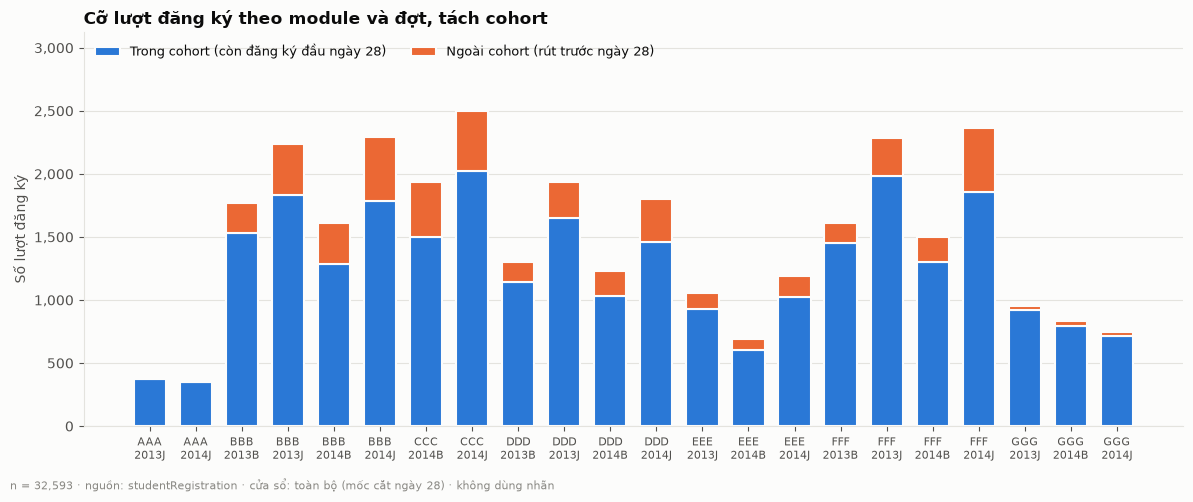

đã lưu: w2_03_cohort_size_by_module.png + w2_03_cohort_size_by_module.csv


,code_module,code_presentation,in_cohort,registered,excluded_early,pct_excluded
6,CCC,2014B,1500,1936,436,0.2252
5,BBB,2014J,1787,2292,505,0.2203
18,FFF,2014J,1860,2365,505,0.2135
4,BBB,2014B,1282,1613,331,0.2052
7,CCC,2014J,2023,2498,475,0.1902


In [7]:
reg = student_reg.assign(in_cohort=~(student_reg["date_unregistration"] < CUTOFF_DAY))
g = (reg.groupby(["code_module", "code_presentation"])["in_cohort"]
        .agg(in_cohort="sum", registered="size").reset_index())
g["excluded_early"] = g["registered"] - g["in_cohort"]
g["pct_excluded"] = (g["excluded_early"] / g["registered"]).round(4)
g["label"] = g["code_module"] + "\n" + g["code_presentation"]

fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(g))
ax.bar(x, g["in_cohort"], width=0.7, color=BLUE, edgecolor=SURFACE, linewidth=1.5, label="Trong cohort (còn đăng ký đầu ngày 28)")
ax.bar(x, g["excluded_early"], bottom=g["in_cohort"], width=0.7, color=ORANGE, edgecolor=SURFACE,
       linewidth=1.5, label="Ngoài cohort (rút trước ngày 28)")
ax.set_xticks(x); ax.set_xticklabels(g["label"], fontsize=8)
ax.yaxis.set_major_formatter(FMT_INT)
ax.set_ylabel("Số lượt đăng ký")
ax.grid(axis="x", visible=False)
ax.set_ylim(0, g["registered"].max() * 1.25)          # chừa chỗ cho chú thích, không đè lên cột
ax.legend(loc="upper left", fontsize=9, ncol=2)
ax.set_title("Cỡ lượt đăng ký theo module và đợt, tách cohort")

finish(fig, "w2_03", "cohort_size_by_module", "Cỡ lượt đăng ký và cohort theo module/đợt",
       "studentRegistration", N_ALL, f"toàn bộ (mốc cắt ngày {CUTOFF_DAY})", False,
       g.drop(columns="label"))
display(g.drop(columns="label").sort_values("pct_excluded", ascending=False).head(5))
SUMMARY["w2_03"] = dict(max_excl_pct=float(g["pct_excluded"].max()),
                        max_excl_where=g.loc[g["pct_excluded"].idxmax(), "label"].replace("\n", " "),
                        min_excl_pct=float(g["pct_excluded"].min()),
                        smallest_n=int(g["registered"].min()))

## 5. Manifest và tóm tắt số liệu

`eda_manifest.csv` liệt kê mỗi hình kèm n, nguồn, cửa sổ, có dùng nhãn hay không. `eda_week2_summary.md` gom các con số chính để đối chiếu.

In [26]:
manifest = pd.DataFrame(MANIFEST)
manifest.to_csv(EDA_DIR / "eda_manifest.csv", index=False, encoding="utf-8-sig")
display(manifest)

S = SUMMARY
w1 = S["w2_01"]; w2 = S["w2_02"]; w3 = S["w2_03"]
def pct(x, n=N_ALL): return f"{x / n:.2%}"

lines = [
    "# Tóm tắt EDA tuần 2 (Đạt)", "",
    f"cutoff_day = {CUTOFF_DAY}. Số liệu đều từ toàn bộ dữ liệu thô; không có biểu đồ nào dùng nhãn để chọn feature.", "",
    "## Số liệu chính để đối chiếu với Trường (mục D)", "",
    f"- Tổng lượt đăng ký: **{w2['n_all']:,}**.",
    f"- Rút trước ngày {CUTOFF_DAY} (ngoài cohort): **{w2['n_early']:,}** ({pct(w2['n_early'])}), trong đó rút trước ngày bắt đầu khóa: {w2['n_neg']:,}.",
    f"- Cohort (còn đăng ký đầu ngày {CUTOFF_DAY}): **{w2['n_cohort']:,}**.",
    "- final_result (toàn bộ): " + "; ".join(f"{k} {v:,} ({pct(v)})" for k, v in w1.items()) + ".",
    f"- Withdrawn nhưng trống date_unregistration: **{S['wd_without_unreg']:,}**; có date_unregistration nhưng không Withdrawn: **{S['unreg_not_wd']:,}**. "
    "Nếu khác 0, báo Trường vì ảnh hưởng cách xác định cohort và nhãn.",
    f"- Tỉ lệ rút sớm theo module/đợt dao động {w3['min_excl_pct']:.1%} đến {w3['max_excl_pct']:.1%} (cao nhất: {w3['max_excl_where']}); đợt nhỏ nhất có {w3['smallest_n']:,} lượt đăng ký.",
    "",
    "## Danh sách hình", "",
]
if "w2_02b" in S:
    idx = lines.index("## Danh sách hình")
    lines.insert(idx - 1, "- Đỉnh rút lui (ngày -30..60): " + "; ".join(
        f"ngày {r['day']} = {r['n_day']:,} lượt, lớn nhất {r['mp']} ({r['share']:.0%})" for r in S["w2_02b"]) + ".")
lines += [f"- `{r.png}` (n = {r.n:,}, nguồn: {r.source}, nhãn: {r.label_used})" for r in manifest.itertuples()]
(EDA_DIR / "eda_week2_summary.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

,chart_id,title,source,n,window,label_used,png,csv
0,w2_01,Phân bố final_result,studentInfo,32593,toàn bộ (không áp dụng),"có (mô tả, toàn bộ)",w2_01_final_result.png,w2_01_final_result.csv
1,w2_02,Rút lui tích lũy theo ngày,studentRegistration,32593,toàn bộ (mốc cắt ngày 28),không,w2_02_withdrawn_cumulative.png,w2_02_withdrawn_cumulative.csv
2,w2_02b,Đỉnh rút lui theo ngày và module/đợt đóng góp,studentRegistration,5118,"toàn bộ, ngày -30 đến 60",không,w2_02b_withdrawn_spikes.png,w2_02b_withdrawn_spikes.csv
3,w2_03,Cỡ lượt đăng ký và cohort theo module/đợt,studentRegistration,32593,toàn bộ (mốc cắt ngày 28),không,w2_03_cohort_size_by_module.png,w2_03_cohort_size_by_module.csv


# Tóm tắt EDA tuần 2 (Đạt)

cutoff_day = 28. Số liệu đều từ toàn bộ dữ liệu thô; không có biểu đồ nào dùng nhãn để chọn feature.

## Số liệu chính để đối chiếu với Trường (mục D)

- Tổng lượt đăng ký: **32,593**.
- Rút trước ngày 28 (ngoài cohort): **5,040** (15.46%), trong đó rút trước ngày bắt đầu khóa: 2,678.
- Cohort (còn đăng ký đầu ngày 28): **27,553**.
- final_result (toàn bộ): Distinction 3,024 (9.28%); Pass 12,361 (37.93%); Fail 7,052 (21.64%); Withdrawn 10,156 (31.16%).
- Withdrawn nhưng trống date_unregistration: **93**; có date_unregistration nhưng không Withdrawn: **9**. Nếu khác 0, báo Trường vì ảnh hưởng cách xác định cohort và nhãn.
- Tỉ lệ rút sớm theo module/đợt dao động 2.9% đến 22.5% (cao nhất: CCC 2014B); đợt nhỏ nhất có 365 lượt đăng ký.
- Đỉnh rút lui (ngày -30..60): ngày 12 = 788 lượt, lớn nhất FFF 2014J (28%); ngày 0 = 419 lượt, lớn nhất BBB 2013J (24%); ngày 27 = 170 lượt, lớn nhất BBB 2013B (35%).

## Danh sách hình

- `w2_01_final_result.png` (n = 32,593, ng

# Phần 2 · EDA có nhãn trên tập train, tuần 3

In [9]:
# ---- Phần 2: nhóm kết quả cố định, hàm lưu hình và manifest tuần 3 ----
plt.rcParams["axes.titlesize"] = 11.5
GROUPS = ["Withdrawn", "Fail", "Pass", "Distinction"]          # thứ tự cố định, không đổi theo bộ lọc
GCOL = {"Withdrawn": ORANGE, "Fail": BLUE, "Pass": AQUA, "Distinction": YELLOW}
GMARK = {"Withdrawn": "o", "Fail": "s", "Pass": "^", "Distinction": "D"}
MANIFEST_W3 = []
def finish_w3(fig, cid, slug, title, source, n_text, window, data, top=0.94):
    fig.text(0.01, 0.006, f"n = {n_text} · nguồn: {source} · cửa sổ: {window} · nhãn: chỉ tập train",
             fontsize=8, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.035, 1, top))
    png, csv = EDA_DIR / f"{cid}_{slug}.png", EDA_DIR / f"{cid}_{slug}.csv"
    fig.savefig(png, dpi=150)
    data.to_csv(csv, index=False, encoding="utf-8-sig")
    MANIFEST_W3.append(dict(chart_id=cid, title=title, source=source, n=str(n_text), window=window,
                         label_used="có (chỉ train)", png=png.name, csv=csv.name))
    plt.show()
    print("đã lưu:", png.name, "+", csv.name)

def wilson(k, n, z=1.96):
    k, n = np.asarray(k, float), np.asarray(n, float)
    p = k / n
    denom = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / denom
    return centre - half, centre + half

## 1. Đọc bảng feature, split và dữ liệu thô cần đối chiếu

In [10]:
NA = ["?", ""]
missing_inputs = [p for p in (FEATURE_PATH, SPLIT_PATH) if not p.exists()]
if missing_inputs:
    raise FileNotFoundError(
        f"Chưa có {[str(p) for p in missing_inputs]}. Notebook này chỉ chạy được sau khi Trường giao "
        "feature_28d.csv và split.csv vào data/processed/ (hoặc đặt OULAD_FEATURE_PATH / OULAD_SPLIT_PATH).")

feat = pd.read_csv(FEATURE_PATH)
split = pd.read_csv(SPLIT_PATH)[["id_student", "split"]].drop_duplicates()
assert split["id_student"].is_unique, "split.csv: một id_student có nhiều hơn một tập"
feat = feat.drop(columns=["split"], errors="ignore").merge(split, on="id_student", how="left", validate="many_to_one")
ORIG_COLUMNS = list(feat.columns)      # cột gốc của bảng feature, trước khi ghép final_result để chia nhóm

# --- bảng của Trường giữ nhiều cột tĩnh ở dạng chuỗi gốc; mã hóa thành số CHỈ trong notebook này (không ghi lại file) ---
EDU_MAP = {"No Formal quals": 0, "Lower Than A Level": 1, "A Level or Equivalent": 2, "HE Qualification": 3, "Post Graduate Qualification": 4}
AGE_MAP = {"0-35": 0, "35-55": 1, "55<=": 2}
IMD_RAW_QMARK = 0
if "imd_band" in feat.columns and feat["imd_band"].dtype == object or str(feat["imd_band"].dtype).startswith("str"):
    IMD_RAW_QMARK = int(feat["imd_band"].astype(str).str.strip().eq("?").sum())
    lead = pd.to_numeric(feat["imd_band"].astype("string").str.extract(r"^\s*(\d+)", expand=False), errors="coerce")
    feat["imd_band"] = (lead // 10).astype("float64")          # '?' -> NaN; '10-20' (không có %) vẫn đúng
if feat["highest_education"].map(type).eq(str).any():
    feat["highest_education"] = feat["highest_education"].map(EDU_MAP).astype("float64")
if feat["age_band"].map(type).eq(str).any():
    feat["age_band"] = feat["age_band"].map(AGE_MAP).astype("float64")
if feat["disability"].map(type).eq(str).any():
    feat["disability"] = feat["disability"].map({"N": 0, "Y": 1}).astype("float64")
print("Đã mã hóa số trong notebook:", [c for c in ["imd_band", "highest_education", "age_band", "disability"] if c in feat.columns])
print("feature_28d:", feat.shape, "| split:", feat["split"].value_counts(dropna=False).to_dict())

def onehot_decode(df, prefix):
    # khôi phục nhãn phân loại từ các cột one-hot <prefix>_<giá trị>
    cols = [c for c in df.columns if c.startswith(prefix + "_") and c != "imd_missing"]
    if not cols:
        return None
    arr = df[cols].to_numpy()
    names = np.array([c[len(prefix) + 1:].replace("_", " ") for c in cols], dtype=object)
    out = pd.Series(names[arr.argmax(axis=1)], index=df.index, dtype=object)
    out[arr.max(axis=1) <= 0] = np.nan
    return out

if "code_module" not in feat.columns:
    cm = onehot_decode(feat, "code_module")
    if cm is None:
        raise ValueError("feature_28d thiếu code_module (và không có cột one-hot code_module_*); không ghép được khóa.")
    feat.insert(1, "code_module", cm.str.replace(" ", ""))
missing_keys = [k for k in KEYS if k not in feat.columns]
assert not missing_keys, f"feature_28d thiếu khóa {missing_keys}"
assert not feat.duplicated(KEYS).any(), "feature_28d: khóa lượt đăng ký bị trùng"

BEHAVIOR_NUMERIC = ["total_clicks", "active_days", "clicks_per_active_day", "clicks_w1", "clicks_w2", "clicks_w3",
                    "clicks_w4", "click_trend", "n_distinct_sites", "n_distinct_activity_types", "first_active_day",
                    "last_active_day", "days_since_last_active", "longest_gap_days", "n_assess_due",
                    "n_assess_submitted", "assess_submit_rate", "avg_score", "weighted_score"]
BEHAVIOR_FLAGS = ["no_activity_flag", "no_assess_flag"]
need = ["label_withdrawn"] + BEHAVIOR_NUMERIC + BEHAVIOR_FLAGS
lack = [c for c in need if c not in feat.columns]
assert not lack, f"feature_28d thiếu cột theo đặc tả: {lack} (đối chiếu config/columns.yaml của Trường)"
STATIC_NUMERIC = [c for c in ["studied_credits", "num_of_prev_attempts", "date_registration",
                              "highest_education", "imd_band", "age_band"] if c in feat.columns]

# --- dữ liệu thô: final_result (CHỈ để chia nhóm khi vẽ), đăng ký, bài đánh giá ---
if not (RAW_DIR / "studentInfo.csv").exists():
    raise FileNotFoundError(f"Không thấy dữ liệu thô trong {RAW_DIR}. Cần studentInfo, studentRegistration, assessments, studentVle (đặt OULAD_RAW_DIR nếu để chỗ khác).")
info = pd.read_csv(RAW_DIR / "studentInfo.csv", na_values=NA, dtype={"id_student": "int32"})
reg = pd.read_csv(RAW_DIR / "studentRegistration.csv", na_values=NA, dtype={"id_student": "int32"})
assessments = pd.read_csv(RAW_DIR / "assessments.csv", na_values=NA)
feat = feat.merge(info[KEYS + ["final_result"]], on=KEYS, how="left", validate="one_to_one")
assert feat["final_result"].notna().all(), "có lượt đăng ký trong feature_28d không có trong studentInfo"
feat["outcome"] = feat["final_result"]
SUMMARY_W3 = {}

Đã mã hóa số trong notebook: ['imd_band', 'highest_education', 'age_band', 'disability']
feature_28d: (27553, 37) | split: {'train': 19264, 'test': 4158, 'dev': 4131}


## 2. Đối chiếu số liệu và kiểm tra tách tập

Chỉ đếm và so sánh, không vẽ theo nhãn. Làm trước khi vẽ để biết bảng feature có khớp dữ liệu thô không. Phần kiểm tra click đọc `studentVle` trong cửa sổ 0–27 và **cộng dồn mọi dòng** (kể cả dòng trùng).

In [11]:
CHECKS = []
def check(name, ok, detail=""):
    CHECKS.append(dict(check=name, ket_qua="ĐẠT" if ok else "LỆCH", chi_tiet=detail))
    print(f"[{'ĐẠT' if ok else 'LỆCH'}] {name} {detail}")

# 1. Cỡ cohort: còn đăng ký ở đầu ngày 28
n_cohort_raw = int((~(reg["date_unregistration"] < CUTOFF_DAY)).sum())
check("Số dòng feature_28d = cohort tính từ dữ liệu thô", len(feat) == n_cohort_raw,
      f"(feature {len(feat):,} | cohort thô {n_cohort_raw:,})")

# 2. Mỗi id_student chỉ ở một tập; có đủ 3 tập; không dòng nào thiếu split
per_student = feat.groupby("id_student")["split"].nunique()
check("Mỗi id_student chỉ thuộc một tập", int((per_student > 1).sum()) == 0, f"({int((per_student > 1).sum())} sinh viên ở nhiều tập)")
check("Mọi dòng đều có split và đủ train/dev/test",
      feat["split"].notna().all() and {"train", "dev", "test"} <= set(feat["split"].dropna().unique()),
      f"({feat['split'].value_counts(dropna=False).to_dict()})")

# 3. Cột cấm
bad_cols = [c for c in ["final_result", "date_unregistration"] if c in ORIG_COLUMNS]
check("Bảng feature không chứa final_result / date_unregistration", not bad_cols, f"({bad_cols})" if bad_cols else "")

# 4. label_withdrawn khớp final_result
mism = int((feat["label_withdrawn"].astype(int) != feat["final_result"].eq("Withdrawn").astype(int)).sum())
check("label_withdrawn khớp final_result == Withdrawn", mism == 0, f"({mism} dòng lệch)")

# 5. Tỉ lệ nhãn theo tập
rate = feat.groupby("split")["label_withdrawn"].agg(n="size", n_positive="sum", positive_rate="mean")
display(rate)
SUMMARY_W3["split_rate"] = rate.reset_index().to_dict("records")

# 6. Cộng dồn click trong cửa sổ 0–27 từ studentVle thô, so với bảng feature
svle = pd.read_csv(RAW_DIR / "studentVle.csv", na_values=NA, usecols=KEYS + ["date", "sum_click"],
                   dtype={"id_student": "int32", "date": "int16", "sum_click": "int32",
                          "code_module": "category", "code_presentation": "category"})
w = svle[(svle["date"] >= 0) & (svle["date"] < CUTOFF_DAY)]
w = w.astype({"code_module": str, "code_presentation": str})
agg = (w.groupby(KEYS)
         .agg(raw_total_clicks=("sum_click", "sum"), raw_active_days=("date", "nunique")).reset_index())
del svle, w
chk = feat[KEYS + ["total_clicks", "active_days"]].merge(agg, on=KEYS, how="left")
chk[["raw_total_clicks", "raw_active_days"]] = chk[["raw_total_clicks", "raw_active_days"]].fillna(0)
bad_clicks = chk[~np.isclose(chk["total_clicks"], chk["raw_total_clicks"])]
bad_days = chk[chk["active_days"] != chk["raw_active_days"]]
check("total_clicks khớp tổng sum_click thô trong ngày 0–27 (mọi dòng)", len(bad_clicks) == 0,
      f"({len(bad_clicks):,} / {len(chk):,} dòng lệch)")
check("active_days khớp số ngày khác nhau có click trong ngày 0–27", len(bad_days) == 0,
      f"({len(bad_days):,} / {len(chk):,} dòng lệch)")
if len(bad_clicks) or len(bad_days):
    out = pd.concat([bad_clicks, bad_days]).drop_duplicates(KEYS)
    out.head(200).to_csv(EDA_DIR / "w3_reconciliation_mismatch.csv", index=False)
    print("Ví dụ dòng lệch (đã lưu tối đa 200 dòng vào w3_reconciliation_mismatch.csv):")
    display(out.head(8))

# 6b. cờ thiếu có khớp giá trị thiếu không (imd_band '?' trong file gốc phải bật imd_missing)
n_imd_na = int(feat["imd_band"].isna().sum()); n_imd_flag = int(feat["imd_missing"].sum())
check("imd_missing khớp số imd_band thiếu ('?')", n_imd_na == n_imd_flag,
      f"(imd_band thiếu {n_imd_na:,} | imd_missing = 1: {n_imd_flag:,})")
n_dr_na = int(feat["date_registration"].isna().sum()); n_dr_flag = int(feat["date_registration_missing"].sum())
check("date_registration_missing khớp số date_registration thiếu", n_dr_na == n_dr_flag, f"({n_dr_na} | {n_dr_flag})")
check("no_activity_flag = 1 đúng khi total_clicks = 0", bool((feat["no_activity_flag"] == (feat["total_clicks"] == 0).astype(int)).all()))

# 7. Tổng click 4 tuần = total_clicks
wk_sum = feat[["clicks_w1", "clicks_w2", "clicks_w3", "clicks_w4"]].sum(axis=1)
bad_wk = int((~np.isclose(wk_sum, feat["total_clicks"])).sum())
check("clicks_w1+w2+w3+w4 = total_clicks", bad_wk == 0, f"({bad_wk:,} dòng lệch)")

recon = pd.DataFrame(CHECKS)
recon.to_csv(EDA_DIR / "w3_reconciliation.csv", index=False, encoding="utf-8-sig")
SUMMARY_W3["checks"] = CHECKS

[ĐẠT] Số dòng feature_28d = cohort tính từ dữ liệu thô (feature 27,553 | cohort thô 27,553)
[ĐẠT] Mỗi id_student chỉ thuộc một tập (0 sinh viên ở nhiều tập)
[ĐẠT] Mọi dòng đều có split và đủ train/dev/test ({'train': 19264, 'test': 4158, 'dev': 4131})
[ĐẠT] Bảng feature không chứa final_result / date_unregistration 
[ĐẠT] label_withdrawn khớp final_result == Withdrawn (0 dòng lệch)


,n,n_positive,positive_rate
split,,,
dev,4131,751,0.181796
test,4158,791,0.190236
train,19264,3582,0.185943


[ĐẠT] total_clicks khớp tổng sum_click thô trong ngày 0–27 (mọi dòng) (0 / 27,553 dòng lệch)
[ĐẠT] active_days khớp số ngày khác nhau có click trong ngày 0–27 (0 / 27,553 dòng lệch)
[ĐẠT] imd_missing khớp số imd_band thiếu ('?') (imd_band thiếu 1,029 | imd_missing = 1: 1,029)
[ĐẠT] date_registration_missing khớp số date_registration thiếu (7 | 7)
[ĐẠT] no_activity_flag = 1 đúng khi total_clicks = 0 
[ĐẠT] clicks_w1+w2+w3+w4 = total_clicks (0 dòng lệch)


In [12]:
# ---- chỉ tập train được dùng từ đây trở xuống ----
train = feat[feat["split"] == "train"].copy()
assert len(train) > 0 and set(train["split"]) == {"train"}
N_TRAIN = len(train)
POS_RATE = float(train["label_withdrawn"].mean())
n_by = train["outcome"].value_counts().reindex(GROUPS).fillna(0).astype(int)
print(f"train: {N_TRAIN:,} lượt đăng ký / {train['id_student'].nunique():,} sinh viên; "
      f"tỉ lệ Withdrawn (nhãn dương) = {POS_RATE:.2%}")
print(n_by.to_dict())
SUMMARY_W3["train"] = dict(n=N_TRAIN, students=int(train["id_student"].nunique()), pos_rate=POS_RATE, groups=n_by.to_dict())

train: 19,264 lượt đăng ký / 17,394 sinh viên; tỉ lệ Withdrawn (nhãn dương) = 18.59%
{'Withdrawn': 3582, 'Fail': 4931, 'Pass': 8678, 'Distinction': 2073}


## 3. w3_04 · Click theo tuần trong cửa sổ 28 ngày

Bốn tuần của cửa sổ 0–27 (tuần 1 = ngày 0–6, …, tuần 4 = ngày 21–27, theo đặc tả `clicks_w1..w4`; xác nhận lại với `columns.yaml` của Trường). Trung bình và trung vị cạnh nhau vì click lệch phải mạnh. Fail và Withdrawn tách riêng.

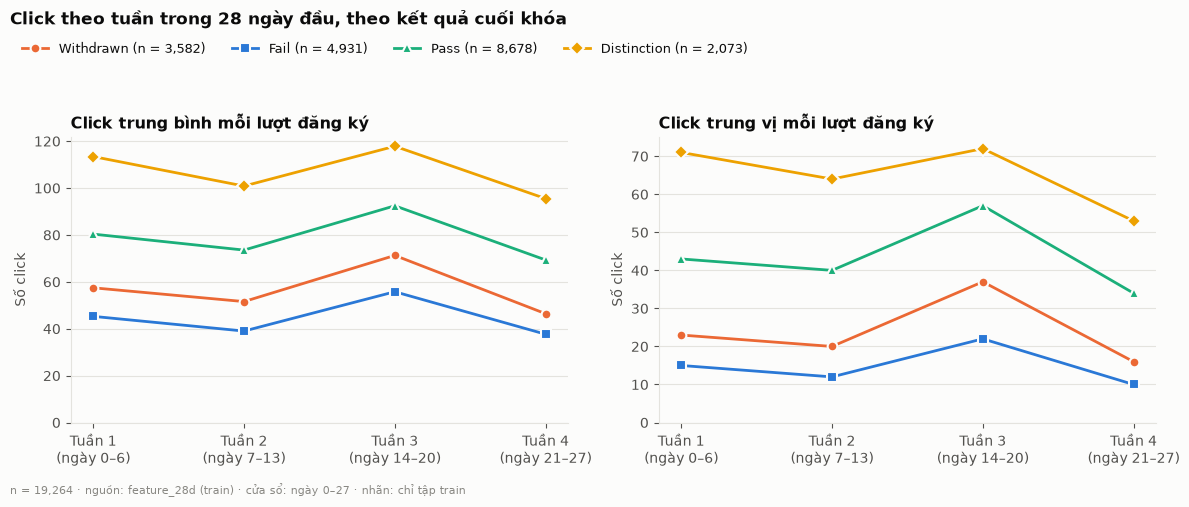

đã lưu: w3_04_clicks_by_week.png + w3_04_clicks_by_week.csv


In [13]:
WK = ["clicks_w1", "clicks_w2", "clicks_w3", "clicks_w4"]
WK_LABELS = ["Tuần 1\n(ngày 0–6)", "Tuần 2\n(ngày 7–13)", "Tuần 3\n(ngày 14–20)", "Tuần 4\n(ngày 21–27)"]
g = train.groupby("outcome")[WK]
mean_df, med_df = g.mean().reindex(GROUPS), g.median().reindex(GROUPS)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, tab, ttl in ((axes[0], mean_df, "Click trung bình mỗi lượt đăng ký"),
                     (axes[1], med_df, "Click trung vị mỗi lượt đăng ký")):
    for gname in GROUPS:
        ax.plot(range(4), tab.loc[gname].values, color=GCOL[gname], marker=GMARK[gname], lw=2, ms=7,
                mec=SURFACE, mew=1.5, label=f"{gname} (n = {n_by[gname]:,})")
    ax.set_xticks(range(4)); ax.set_xticklabels(WK_LABELS)
    ax.set_ylim(bottom=0)
    ax.yaxis.set_major_formatter(FMT_INT)
    ax.set_ylabel("Số click")
    ax.grid(axis="x", visible=False)
    ax.set_title(ttl)
h_, l_ = axes[0].get_legend_handles_labels()
fig.legend(h_, l_, loc="upper left", bbox_to_anchor=(0.01, 0.94), ncol=4, fontsize=9.5)   # ngoài vùng vẽ, không đè đường
fig.suptitle("Click theo tuần trong 28 ngày đầu, theo kết quả cuối khóa", x=0.01, ha="left", fontsize=12.5, fontweight="bold")

d4 = pd.concat([mean_df.stack().rename("mean"), med_df.stack().rename("median")], axis=1).reset_index()
d4.columns = ["outcome", "week_column", "mean_clicks", "median_clicks"]
d4["n_group"] = d4["outcome"].map(n_by)
finish_w3(fig, "w3_04", "clicks_by_week", "Click theo tuần theo nhóm kết quả", "feature_28d (train)",
       f"{N_TRAIN:,}", WINDOW, d4, top=0.87)
SUMMARY_W3["w3_04"] = dict(median_w1_w4={gn: [float(x) for x in med_df.loc[gn].values] for gn in GROUPS},
                        mean_w1_w4={gn: [float(x) for x in mean_df.loc[gn].values] for gn in GROUPS})

## 4. w3_05 · Số ngày hoạt động và click mỗi ngày hoạt động theo nhãn

Hộp: trung vị (vạch đậm), Q1–Q3, râu P5–P95; không vẽ điểm ngoại lai. Trục click mỗi ngày dùng thang symlog để thấy cả nhóm giá trị bằng 0.

,outcome,n,active_days_median,active_days_q1,active_days_q3,clicks_per_active_day_median,no_activity_rate
0,Withdrawn,3582,8.0,4.0,13.0,17.000000,0.061418
1,Fail,4931,6.0,3.0,11.0,15.250000,0.100588
2,Pass,8678,11.0,6.0,17.0,19.906926,0.016363
3,Distinction,2073,14.0,8.0,20.0,22.500000,0.011577


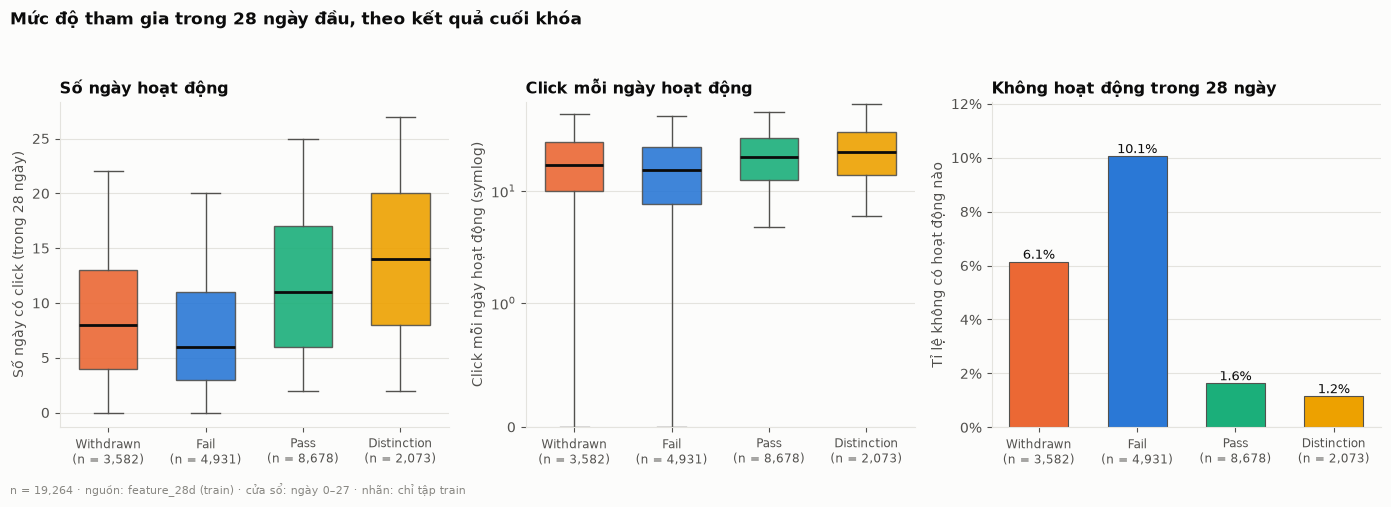

đã lưu: w3_05_engagement.png + w3_05_engagement.csv


In [14]:
def box_by_group(ax, col, ylabel, title, symlog=False):
    data = [train.loc[train["outcome"] == gname, col].dropna().to_numpy() for gname in GROUPS]
    bp = ax.boxplot(data, positions=range(len(GROUPS)), widths=0.6, patch_artist=True, whis=(5, 95),
                    showfliers=False, medianprops=dict(color=INK, lw=2),
                    whiskerprops=dict(color=INK2, lw=1), capprops=dict(color=INK2, lw=1))
    for patch, gname in zip(bp["boxes"], GROUPS):
        patch.set_facecolor(GCOL[gname]); patch.set_edgecolor(INK2); patch.set_alpha(0.9)
    ax.set_xticks(range(len(GROUPS)))
    ax.set_xticklabels([f"{gname}\n(n = {n_by[gname]:,})" for gname in GROUPS], fontsize=8.5)
    if symlog:
        ax.set_yscale("symlog", linthresh=1); ax.set_ylim(bottom=0)
    ax.set_ylabel(ylabel); ax.set_title(title)
    ax.grid(axis="x", visible=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))
box_by_group(axes[0], "active_days", "Số ngày có click (trong 28 ngày)", "Số ngày hoạt động")
box_by_group(axes[1], "clicks_per_active_day", "Click mỗi ngày hoạt động (symlog)", "Click mỗi ngày hoạt động", symlog=True)
no_act = train.groupby("outcome")["no_activity_flag"].mean().reindex(GROUPS)
ax = axes[2]
ax.bar(range(len(GROUPS)), no_act.values * 100, width=0.6, color=[GCOL[gn] for gn in GROUPS], edgecolor=INK2, linewidth=0.8)
for i, v in enumerate(no_act.values):
    ax.text(i, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(GROUPS)))
ax.set_xticklabels([f"{gname}\n(n = {n_by[gname]:,})" for gname in GROUPS], fontsize=8.5)
ax.set_ylim(0, max(no_act.max() * 100 * 1.2, 1))
ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_ylabel("Tỉ lệ không có hoạt động nào"); ax.set_title("Không hoạt động trong 28 ngày")
ax.grid(axis="x", visible=False)
fig.suptitle("Mức độ tham gia trong 28 ngày đầu, theo kết quả cuối khóa", x=0.01, ha="left", fontsize=12.5, fontweight="bold")

rows5 = []
for gname in GROUPS:
    sub = train[train["outcome"] == gname]
    rows5.append(dict(outcome=gname, n=len(sub),
                      active_days_median=sub["active_days"].median(), active_days_q1=sub["active_days"].quantile(.25),
                      active_days_q3=sub["active_days"].quantile(.75),
                      clicks_per_active_day_median=sub["clicks_per_active_day"].median(),
                      no_activity_rate=sub["no_activity_flag"].mean()))
d5 = pd.DataFrame(rows5)
display(d5)
finish_w3(fig, "w3_05", "engagement", "Số ngày hoạt động và click mỗi ngày theo nhóm kết quả", "feature_28d (train)",
       f"{N_TRAIN:,}", WINDOW, d5)
SUMMARY_W3["w3_05"] = d5.set_index("outcome").to_dict("index")

## 5. w3_06 · Bài nộp và điểm trong 28 ngày; ngày hạn của bài đầu tiên theo module

Trả lời câu hỏi: **điểm có sẵn đến ngày 28 không?** Hai ô đầu dùng train. Ô thứ ba dùng bảng `assessments` (không có nhãn): bài không phải Exam có ngày hạn đầu tiên, so với mốc ngày 28. Module/đợt nào có bài đầu tiên hạn từ ngày 28 trở đi thì **không thể có điểm trước mốc**, nên `avg_score` ở đó luôn là giá trị điền (0 kèm cờ).

,outcome,n,n_assess_due_gt0,share_with_scored_assessment,n_scored,avg_score_median
0,Withdrawn,3582,3206,0.745477,2390,70.0
1,Fail,4931,4039,0.744244,3006,70.0
2,Pass,8678,6981,0.961897,6715,78.0
3,Distinction,2073,1563,0.984645,1539,89.0


,code_module,code_presentation,first_due_day,before_cutoff
0,AAA,2013J,19.0,True
1,AAA,2014J,19.0,True
2,BBB,2013B,19.0,True
3,BBB,2013J,19.0,True
4,BBB,2014B,12.0,True
5,BBB,2014J,19.0,True
6,CCC,2014B,18.0,True
7,CCC,2014J,18.0,True
8,DDD,2013B,23.0,True
9,DDD,2013J,25.0,True


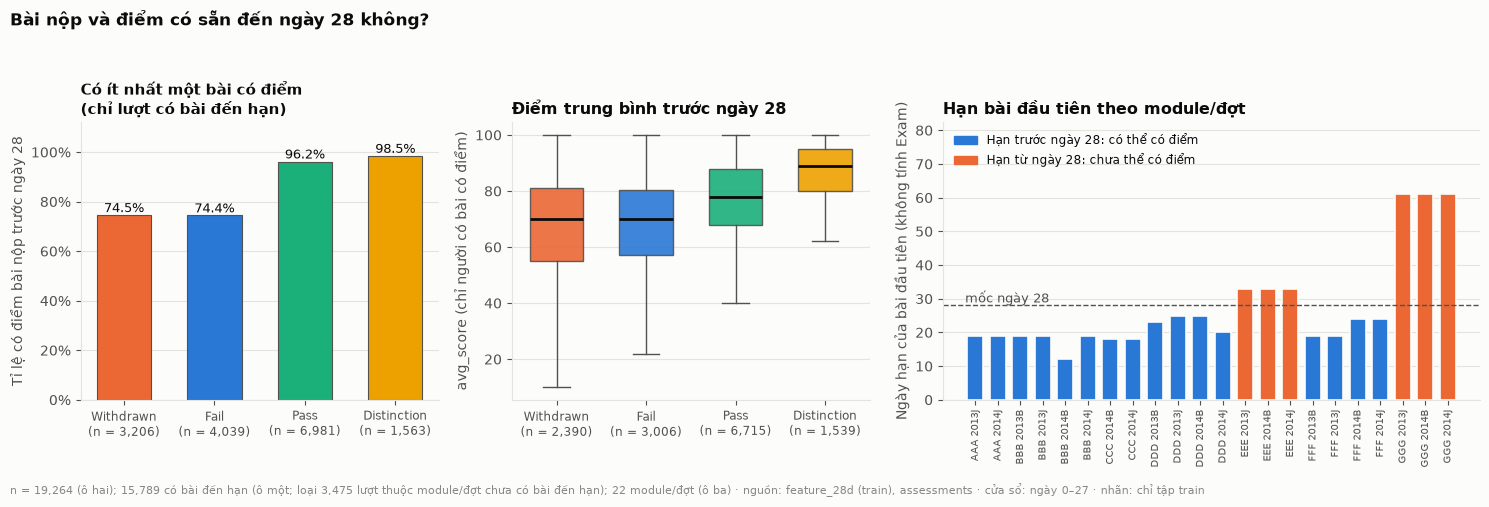

đã lưu: w3_06_assessments.png + w3_06_assessments.csv


In [15]:
# Lượt đăng ký thuộc module/đợt chưa có bài nào đến hạn trước ngày 28 (n_assess_due = 0) KHÔNG thể có điểm,
# nên bị loại khỏi ô đầu; nếu gộp vào, tỉ lệ "có điểm" bị kéo thấp ở mọi nhóm (và nhóm ít Withdrawn bị thiệt hơn).
train_due = train[train["n_assess_due"] > 0]
n_due_by = train_due["outcome"].value_counts().reindex(GROUPS).fillna(0).astype(int)
n_no_due = int((train["n_assess_due"] == 0).sum())
has_scored = 1 - train_due.groupby("outcome")["no_assess_flag"].mean().reindex(GROUPS)
scored_only = train[train["no_assess_flag"] == 0]
n_scored = scored_only["outcome"].value_counts().reindex(GROUPS).fillna(0).astype(int)

non_exam = assessments[(assessments["assessment_type"] != "Exam") & assessments["date"].notna()]
first_due = (non_exam.groupby(["code_module", "code_presentation"])["date"].min().reset_index()
             .rename(columns={"date": "first_due_day"}))
first_due["label"] = first_due["code_module"] + "\n" + first_due["code_presentation"]
first_due["before_cutoff"] = first_due["first_due_day"] < CUTOFF_DAY

fig, axes = plt.subplots(1, 3, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1, 1.5]})
ax = axes[0]
ax.bar(range(len(GROUPS)), has_scored.values * 100, width=0.6, color=[GCOL[gn] for gn in GROUPS], edgecolor=INK2, linewidth=0.8)
for i, v in enumerate(has_scored.values):
    ax.text(i, v * 100, f"{v:.1%}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels([f"{gn}\n(n = {n_due_by[gn]:,})" for gn in GROUPS], fontsize=8.5)
ax.set_ylim(0, 112); ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
ax.set_ylabel("Tỉ lệ có điểm bài nộp trước ngày 28"); ax.set_title("Có ít nhất một bài có điểm\n(chỉ lượt có bài đến hạn)", fontsize=10.5); ax.grid(axis="x", visible=False)

ax = axes[1]
data = [scored_only.loc[scored_only["outcome"] == gn, "avg_score"].dropna().to_numpy() for gn in GROUPS]
bp = ax.boxplot(data, positions=range(len(GROUPS)), widths=0.6, patch_artist=True, whis=(5, 95), showfliers=False,
                medianprops=dict(color=INK, lw=2), whiskerprops=dict(color=INK2), capprops=dict(color=INK2))
for patch, gn in zip(bp["boxes"], GROUPS):
    patch.set_facecolor(GCOL[gn]); patch.set_edgecolor(INK2); patch.set_alpha(0.9)
ax.set_xticks(range(len(GROUPS))); ax.set_xticklabels([f"{gn}\n(n = {n_scored[gn]:,})" for gn in GROUPS], fontsize=8.5)
ax.set_ylabel("avg_score (chỉ người có bài có điểm)"); ax.set_title("Điểm trung bình trước ngày 28"); ax.grid(axis="x", visible=False)

ax = axes[2]
cols = [BLUE if b else ORANGE for b in first_due["before_cutoff"]]
ax.bar(range(len(first_due)), first_due["first_due_day"], width=0.7, color=cols, edgecolor=SURFACE, linewidth=1.2)
ax.axhline(CUTOFF_DAY, color=INK2, lw=1, ls="--")
ax.text(-0.45, CUTOFF_DAY, f"mốc ngày {CUTOFF_DAY}", va="bottom", ha="left", fontsize=9, color=INK2)
ax.set_xticks(range(len(first_due))); ax.set_xticklabels([l.replace("\n", " ") for l in first_due["label"]], fontsize=7.5, rotation=90)
ax.set_ylabel("Ngày hạn của bài đầu tiên (không tính Exam)"); ax.set_title("Hạn bài đầu tiên theo module/đợt")
ax.grid(axis="x", visible=False)
ax.legend(handles=[Patch(color=BLUE, label=f"Hạn trước ngày {CUTOFF_DAY}: có thể có điểm"),
                   Patch(color=ORANGE, label=f"Hạn từ ngày {CUTOFF_DAY}: chưa thể có điểm")],
          loc="upper left", fontsize=8.5)
ax.set_ylim(0, max(first_due["first_due_day"].max() * 1.35, CUTOFF_DAY * 1.5))
fig.suptitle("Bài nộp và điểm có sẵn đến ngày 28 không?", x=0.01, ha="left", fontsize=12.5, fontweight="bold")

d6a = pd.DataFrame({"outcome": GROUPS, "n": n_by.values, "n_assess_due_gt0": n_due_by.values, "share_with_scored_assessment": has_scored.values,
                    "n_scored": n_scored.values,
                    "avg_score_median": [scored_only.loc[scored_only["outcome"] == gn, "avg_score"].median() for gn in GROUPS]})
display(d6a); display(first_due.drop(columns="label"))
d6 = pd.concat([d6a.assign(panel="train_by_outcome"),
                first_due.drop(columns="label").assign(panel="assessments_first_due")], ignore_index=True)
finish_w3(fig, "w3_06", "assessments", "Bài nộp và điểm trong 28 ngày; hạn bài đầu tiên",
       "feature_28d (train), assessments", f"{N_TRAIN:,} (ô hai); {int(n_due_by.sum()):,} có bài đến hạn (ô một; loại {n_no_due:,} lượt thuộc module/đợt chưa có bài đến hạn); {len(first_due)} module/đợt (ô ba)", WINDOW, d6)
SUMMARY_W3["w3_06"] = dict(share_scored=has_scored.to_dict(), n_no_due=n_no_due, n_due=int(n_due_by.sum()),
                        n_mp=len(first_due), n_mp_after_cutoff=int((~first_due["before_cutoff"]).sum()),
                        late_mp=[l.replace("\n", " ") for l in first_due.loc[~first_due["before_cutoff"], "label"]])

## 6. w3_07 · Nhân khẩu học so với tỉ lệ rút lui

Tỉ lệ `label_withdrawn = 1` theo từng nhóm, kèm khoảng tin cậy Wilson 95%. Nhóm dưới 100 dòng tô xám: ước lượng không ổn định, không diễn giải. Đường nét đứt = tỉ lệ chung của train. Đây là mô tả, không phải bằng chứng nhân quả.

Panel dựng được: ['Giới tính', 'Nhóm tuổi', 'Học vấn cao nhất', 'imd_band (0 = thiếu thốn nhất)', 'Khuyết tật', 'Số lần học trước', 'Module', 'Vùng (region)']


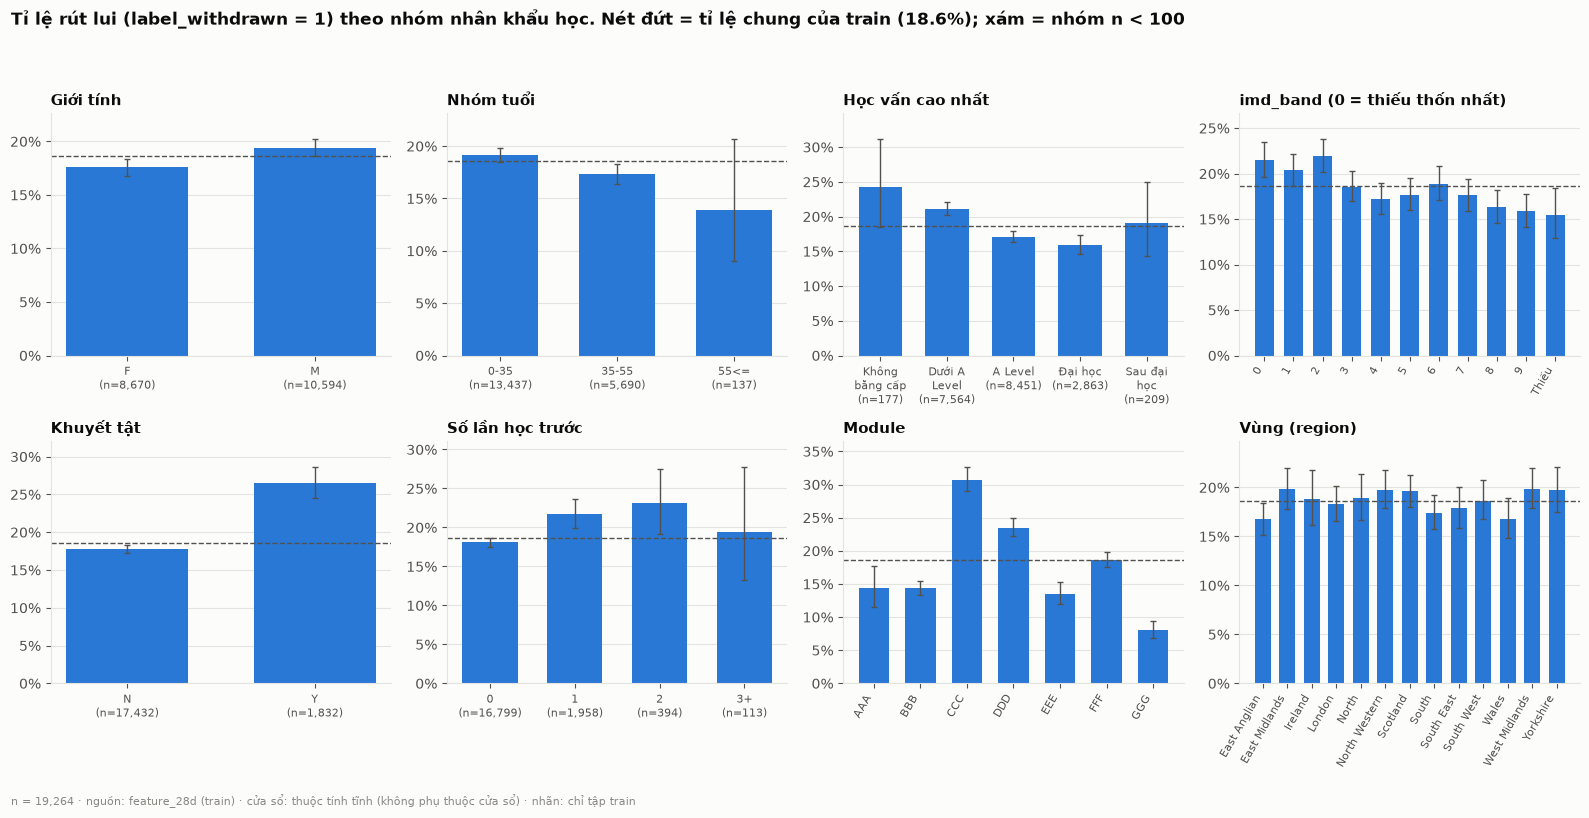

đã lưu: w3_07_demographics_vs_withdrawal.png + w3_07_demographics_vs_withdrawal.csv


,min,max,spread
variable,,,
Module,0.079812,0.307567,0.227755
Khuyết tật,0.177604,0.265284,0.087679
Học vấn cao nhất,0.158924,0.242938,0.084014
imd_band (0 = thiếu thốn nhất),0.154745,0.219407,0.064663
Nhóm tuổi,0.138686,0.191858,0.053172
Số lần học trước,0.181142,0.230964,0.049823
Vùng (region),0.167505,0.198891,0.031386
Giới tính,0.175779,0.194261,0.018482


In [16]:
EDU_LABEL = {0: "Không bằng cấp", 1: "Dưới A Level", 2: "A Level", 3: "Đại học", 4: "Sau đại học"}
AGE_LABEL = {0: "0-35", 1: "35-55", 2: "55<="}

def decode_static(df):
    # trả về {tên panel: (Series nhãn, thứ tự)}; panel nào không giải mã được thì bỏ qua
    out = {}
    def put(name, series, order):
        if series is not None:
            out[name] = (series, order)
    g = onehot_decode(df, "gender") if "gender" not in df.columns else df["gender"]
    put("Giới tính", g, ["F", "M"])
    if "age_band" in df.columns:
        put("Nhóm tuổi", pd.to_numeric(df["age_band"], errors="coerce").round().map(AGE_LABEL), list(AGE_LABEL.values()))
    if "highest_education" in df.columns:
        put("Học vấn cao nhất", pd.to_numeric(df["highest_education"], errors="coerce").round().map(EDU_LABEL), list(EDU_LABEL.values()))
    if "imd_band" in df.columns:
        v = pd.to_numeric(df["imd_band"], errors="coerce").round()
        s = v.astype("Int64").astype(str).where(v.notna(), np.nan)
        if "imd_missing" in df.columns:
            s = s.where(df["imd_missing"] != 1, "Thiếu")
        put("imd_band (0 = thiếu thốn nhất)", s, [str(i) for i in range(10)] + ["Thiếu"])
    if "disability" in df.columns:
        put("Khuyết tật", pd.to_numeric(df["disability"], errors="coerce").round().map({0: "N", 1: "Y"}), ["N", "Y"])
    if "num_of_prev_attempts" in df.columns:
        v = pd.to_numeric(df["num_of_prev_attempts"], errors="coerce").clip(upper=3)
        put("Số lần học trước", v.map(lambda x: "3+" if x == 3 else (str(int(x)) if pd.notna(x) else np.nan)), ["0", "1", "2", "3+"])
    cm = df["code_module"] if "code_module" in df.columns else onehot_decode(df, "code_module")
    put("Module", cm, sorted(cm.dropna().unique()) if cm is not None else [])
    rg = onehot_decode(df, "region") if "region" not in df.columns else df["region"]
    if rg is not None:
        put("Vùng (region)", rg.str.replace(" Region", "", regex=False), sorted(rg.str.replace(" Region", "", regex=False).dropna().unique()))
    return out

panels = decode_static(train)
y = train["label_withdrawn"].astype(int)
print("Panel dựng được:", list(panels))

def rate_table(cat, order):
    d = pd.DataFrame({"cat": cat.astype(object).where(cat.notna(), "Thiếu"), "y": y.values})
    t = d.groupby("cat")["y"].agg(n="size", k="sum")
    t = t.reindex([o for o in order if o in t.index] + [c for c in t.index if c not in order])
    lo, hi = wilson(t["k"], t["n"])
    t["rate"], t["ci_low"], t["ci_high"] = t["k"] / t["n"], lo, hi
    return t.reset_index().rename(columns={"cat": "category", "k": "n_positive"})

ncol = 4
nrow = int(np.ceil(len(panels) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(16, 4.1 * nrow))
axes = np.atleast_1d(axes).ravel()
rows7, SMALL_MIN = [], 100
for ax, (name, (cat, order)) in zip(axes, panels.items()):
    t = rate_table(cat, order)
    cols = [GREY if n < SMALL_MIN else BLUE for n in t["n"]]
    ax.bar(range(len(t)), t["rate"] * 100, width=0.65, color=cols,
           yerr=[(t["rate"] - t["ci_low"]) * 100, (t["ci_high"] - t["rate"]) * 100],
           error_kw=dict(ecolor=INK2, elinewidth=1, capsize=2))
    ax.axhline(POS_RATE * 100, color=INK2, lw=1, ls="--")
    ax.set_xticks(range(len(t)))
    if len(t) <= 6:
        ax.set_xticklabels([f"{textwrap.fill(str(c), 9)}\n(n={n:,})" for c, n in zip(t["category"], t["n"])], fontsize=8)
    else:
        ax.set_xticklabels(t["category"], fontsize=8, rotation=60, ha="right")
    ax.set_ylim(0, max(t["ci_high"].max() * 100 * 1.12, POS_RATE * 100 * 1.2))
    ax.yaxis.set_major_formatter(PercentFormatter(100, decimals=0))
    ax.set_title(name, fontsize=10.5); ax.grid(axis="x", visible=False)
    rows7.append(t.assign(variable=name))
for ax in axes[len(panels):]:
    ax.set_visible(False)
fig.suptitle(f"Tỉ lệ rút lui (label_withdrawn = 1) theo nhóm nhân khẩu học. Nét đứt = tỉ lệ chung của train ({POS_RATE:.1%}); "
             f"xám = nhóm n < {SMALL_MIN}", x=0.01, ha="left", fontsize=12, fontweight="bold")
d7 = pd.concat(rows7, ignore_index=True)[["variable", "category", "n", "n_positive", "rate", "ci_low", "ci_high"]]
finish_w3(fig, "w3_07", "demographics_vs_withdrawal", "Nhân khẩu học so với tỉ lệ rút lui", "feature_28d (train)",
       f"{N_TRAIN:,}", "thuộc tính tĩnh (không phụ thuộc cửa sổ)", d7)

big = d7[d7["n"] >= SMALL_MIN]
spread = (big.groupby("variable")["rate"].agg(["min", "max"]).assign(spread=lambda x: x["max"] - x["min"]).sort_values("spread", ascending=False))
display(spread)
SUMMARY_W3["w3_07"] = {v: dict(min=float(r["min"]), max=float(r["max"])) for v, r in spread.head(4).iterrows()}

## 7. w3_08 · Phân phối feature số và nhận diện lệch phải

Độ lệch (skewness) trên train. Feature **không âm, đủ nhiều giá trị khác nhau và lệch phải mạnh (> 1)** là ứng viên log1p. Quyết định áp dụng log1p do cả nhóm chốt trong `pipeline.py` (fit trên train); notebook này chỉ cung cấp bằng chứng.

,feature,n,n_unique,min,median,p99,max,share_zero,skew_raw,skew_log1p,log1p_candidate
0,clicks_w1,19264,629,0.000000,33.0,493.370000,4385.000000,0.189005,6.600361,-0.452851,True
1,clicks_w4,19264,572,0.000000,24.0,451.000000,2334.000000,0.215168,4.274184,-0.295089,True
2,num_of_prev_attempts,19264,7,0.000000,0.0,2.000000,6.000000,0.872041,3.714716,2.658512,False
3,clicks_w2,19264,585,0.000000,30.0,442.370000,1350.000000,0.194923,3.569213,-0.424744,True
4,total_clicks,19264,1472,0.000000,174.0,1568.740000,4944.000000,0.045785,3.316426,-1.306741,True
5,clicks_w3,19264,614,0.000000,44.0,486.740000,1642.000000,0.166476,2.875243,-0.617779,True
6,first_active_day,19264,29,0.000000,2.0,28.000000,28.000000,0.324076,2.343027,0.684131,True
7,days_since_last_active,19264,29,0.000000,2.0,28.000000,28.000000,0.317847,2.214677,0.612955,True
8,clicks_per_active_day,19264,5416,0.000000,18.4,75.830385,274.666660,0.045785,2.035035,-1.357651,True
9,studied_credits,19264,48,30.000000,60.0,210.000000,630.000000,0.000000,1.768698,0.138120,True


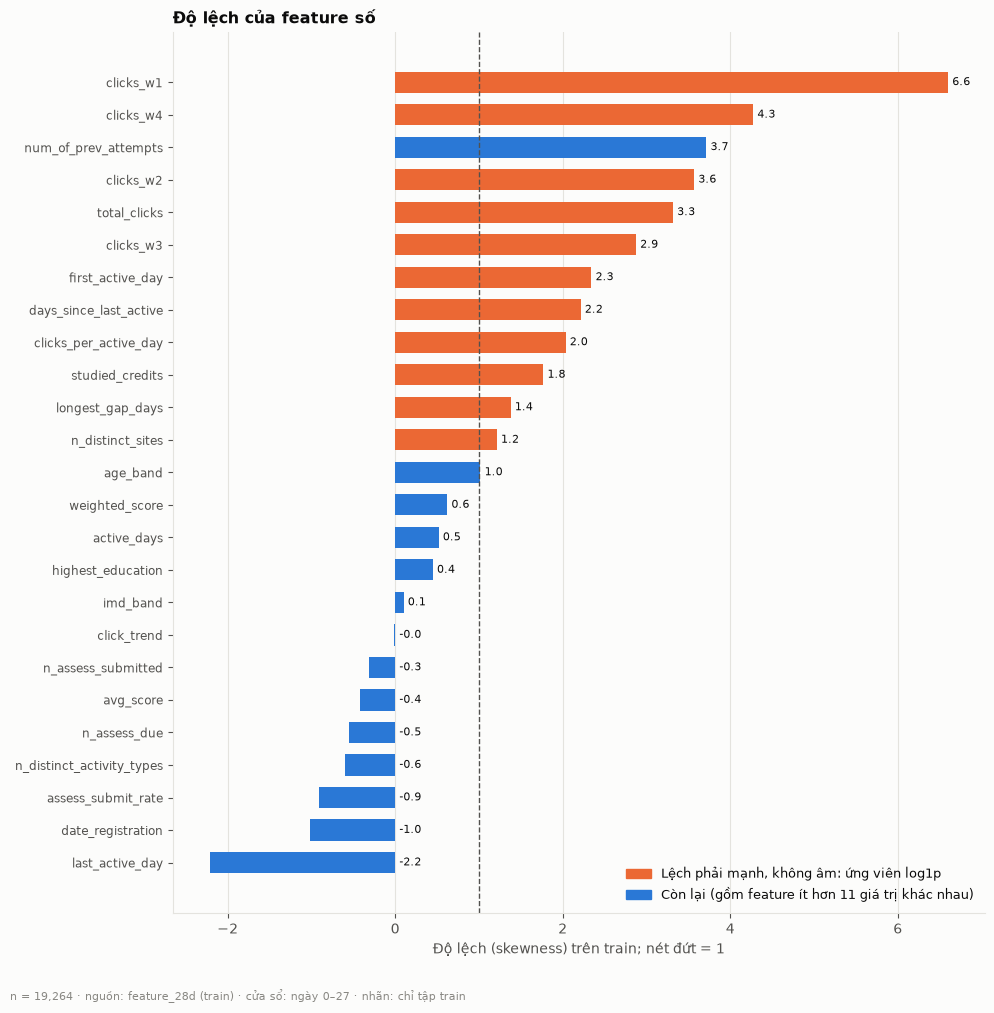

đã lưu: w3_08a_skewness.png + w3_08a_skewness.csv


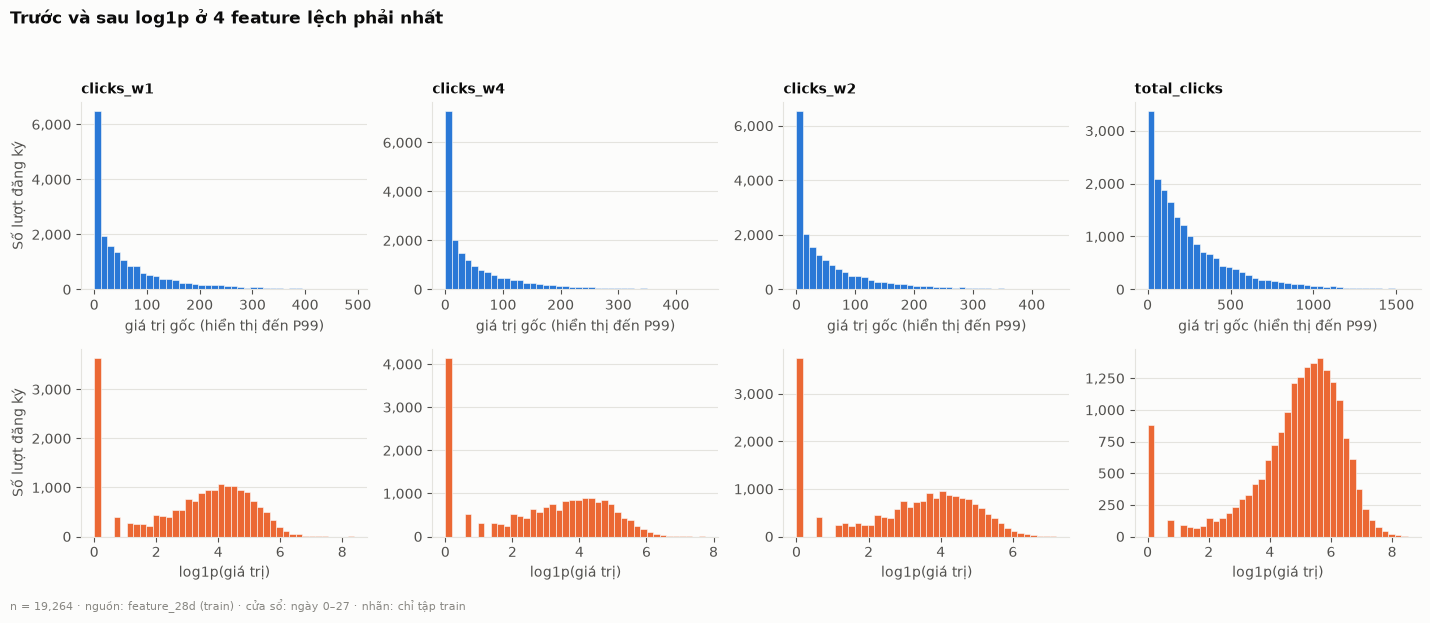

đã lưu: w3_08b_log1p_before_after.png + w3_08b_log1p_before_after.csv


In [17]:
NUMERIC = [c for c in BEHAVIOR_NUMERIC + STATIC_NUMERIC if c in train.columns]
rows8 = []
for c in NUMERIC:
    s = pd.to_numeric(train[c], errors="coerce")
    nn = s.dropna()
    skew_raw = float(nn.skew())
    nonneg = bool(nn.min() >= 0)
    skew_log = float(np.log1p(nn).skew()) if nonneg else np.nan
    rows8.append(dict(feature=c, n=len(nn), n_unique=int(nn.nunique()), min=float(nn.min()), median=float(nn.median()),
                      p99=float(nn.quantile(.99)), max=float(nn.max()), share_zero=float((nn == 0).mean()),
                      skew_raw=skew_raw, skew_log1p=skew_log,
                      log1p_candidate=bool(nonneg and nn.nunique() > 10 and skew_raw > 1)))
d8 = pd.DataFrame(rows8).sort_values("skew_raw", ascending=False).reset_index(drop=True)
display(d8)

plot8 = d8.sort_values("skew_raw")
fig, ax = plt.subplots(figsize=(10, 0.36 * len(plot8) + 1.8))
ax.barh(range(len(plot8)), plot8["skew_raw"], height=0.65,
        color=[ORANGE if c else BLUE for c in plot8["log1p_candidate"]])
ax.axvline(1, color=INK2, lw=1, ls="--")
ax.set_yticks(range(len(plot8))); ax.set_yticklabels(plot8["feature"], fontsize=8.5)
for i, v in enumerate(plot8["skew_raw"]):
    ax.text(max(v, 0) + 0.05, i, f"{v:.1f}", va="center", ha="left", fontsize=8)
ax.set_xlabel("Độ lệch (skewness) trên train; nét đứt = 1")
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=ORANGE, label="Lệch phải mạnh, không âm: ứng viên log1p"), Patch(color=BLUE, label="Còn lại (gồm feature ít hơn 11 giá trị khác nhau)")],
          loc="lower right", fontsize=9)
ax.set_title("Độ lệch của feature số")
finish_w3(fig, "w3_08a", "skewness", "Độ lệch của feature số", "feature_28d (train)", f"{N_TRAIN:,}", WINDOW, d8)

# Lược đồ trước và sau log1p cho 4 feature lệch nhất
top4 = d8[d8["log1p_candidate"]].head(4)["feature"].tolist()
if top4:
    fig, axes = plt.subplots(2, len(top4), figsize=(3.6 * len(top4), 6.2), squeeze=False)
    rows8b = []
    for j, c in enumerate(top4):
        s = pd.to_numeric(train[c], errors="coerce").dropna()
        hi = s.quantile(.99)
        axes[0, j].hist(s[s <= hi], bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.4)
        axes[0, j].set_title(c, fontsize=10); axes[0, j].set_xlabel("giá trị gốc (hiển thị đến P99)")
        axes[1, j].hist(np.log1p(s), bins=40, color=ORANGE, edgecolor=SURFACE, linewidth=0.4)
        axes[1, j].set_xlabel("log1p(giá trị)")
        for k_, (arr, lab) in enumerate(((s[s <= hi], "raw_to_p99"), (np.log1p(s), "log1p"))):
            cnt, edges = np.histogram(arr, bins=40)
            rows8b.append(pd.DataFrame(dict(feature=c, scale=lab, bin_left=edges[:-1], bin_right=edges[1:], n=cnt)))
    for ax in axes.ravel():
        ax.yaxis.set_major_formatter(FMT_INT); ax.grid(axis="x", visible=False)
    axes[0, 0].set_ylabel("Số lượt đăng ký"); axes[1, 0].set_ylabel("Số lượt đăng ký")
    fig.suptitle("Trước và sau log1p ở 4 feature lệch phải nhất", x=0.01, ha="left", fontsize=12.5, fontweight="bold")
    finish_w3(fig, "w3_08b", "log1p_before_after", "Trước và sau log1p", "feature_28d (train)", f"{N_TRAIN:,}", WINDOW,
           pd.concat(rows8b, ignore_index=True))
SUMMARY_W3["w3_08"] = dict(candidates=d8.loc[d8["log1p_candidate"], "feature"].tolist(),
                        skew=d8.set_index("feature")["skew_raw"].round(2).to_dict())

## 8. w3_09 · Ma trận tương quan giữa feature số

Tương quan hạng Spearman (không bị ảnh hưởng bởi lệch phải) trên train. Chỉ ghi số ở ô có |ρ| ≥ 0,8 (nghi đa cộng tuyến). Màu: xanh = âm, cam = dương, xám nhạt = gần 0.

,feature_a,feature_b,spearman
6,last_active_day,days_since_last_active,-1.000000
7,n_assess_submitted,assess_submit_rate,0.959174
4,active_days,longest_gap_days,-0.919561
5,n_distinct_sites,n_distinct_activity_types,0.881259
0,total_clicks,active_days,0.873487
3,total_clicks,n_distinct_sites,0.829596
1,total_clicks,clicks_per_active_day,0.815885
2,total_clicks,clicks_w3,0.812480


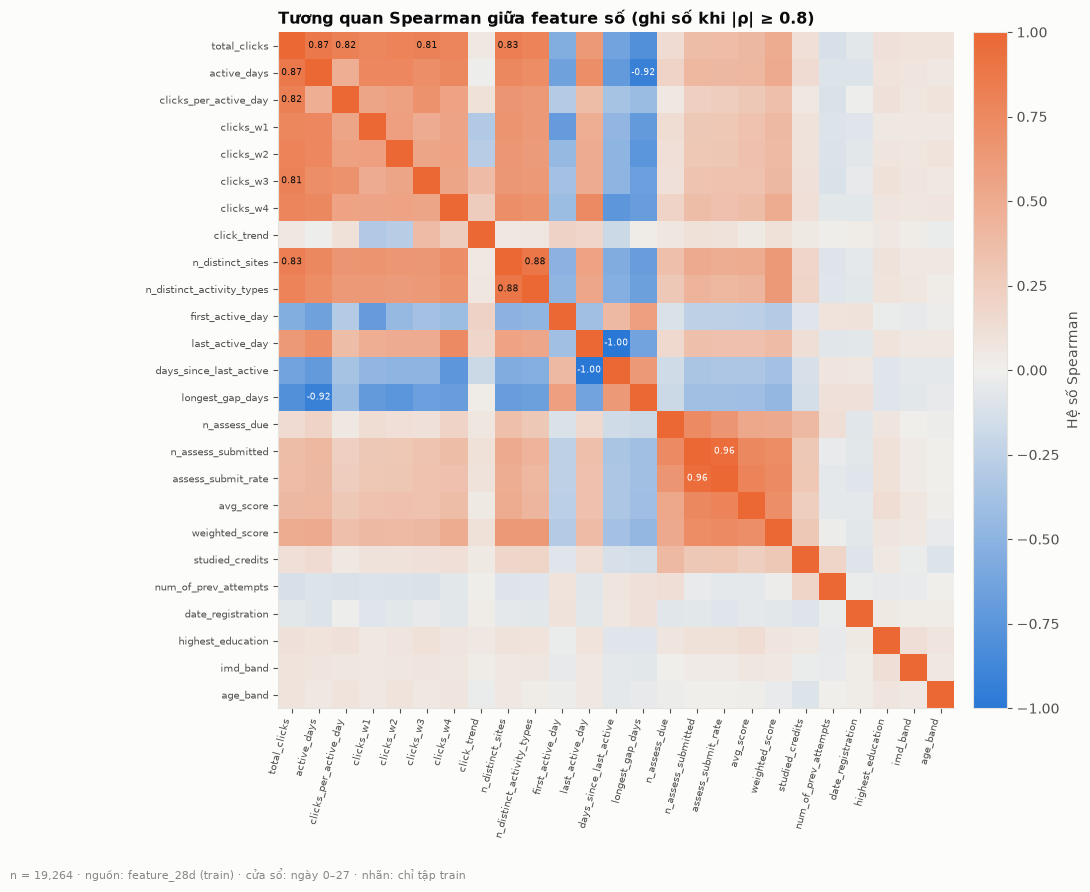

đã lưu: w3_09_correlation.png + w3_09_correlation.csv


In [18]:
corr_cols = [c for c in NUMERIC if train[c].nunique() > 1]
C = train[corr_cols].apply(pd.to_numeric, errors="coerce").corr(method="spearman")
TH = 0.8

fig, ax = plt.subplots(figsize=(11, 9.5))
cmap = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
im = ax.imshow(C.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols))); ax.set_xticklabels(corr_cols, rotation=75, ha="right", fontsize=7.5)
ax.set_yticks(range(len(corr_cols))); ax.set_yticklabels(corr_cols, fontsize=7.5)
ax.grid(False)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        if i != j and abs(C.values[i, j]) >= TH:
            ax.text(j, i, f"{C.values[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                    color="#ffffff" if abs(C.values[i, j]) > 0.9 else INK)
cb = fig.colorbar(im, ax=ax, fraction=0.04, pad=0.02)
cb.set_label("Hệ số Spearman")
ax.set_title(f"Tương quan Spearman giữa feature số (ghi số khi |ρ| ≥ {TH})")

pairs = [(a, b, C.loc[a, b]) for i, a in enumerate(corr_cols) for b in corr_cols[i + 1:] if abs(C.loc[a, b]) >= TH]
pairs_df = (pd.DataFrame(pairs, columns=["feature_a", "feature_b", "spearman"])
              .assign(abs_rho=lambda d: d["spearman"].abs()).sort_values("abs_rho", ascending=False).drop(columns="abs_rho"))
display(pairs_df)
pairs_df.to_csv(EDA_DIR / "w3_09_high_corr_pairs.csv", index=False, encoding="utf-8-sig")
finish_w3(fig, "w3_09", "correlation", "Ma trận tương quan giữa feature số", "feature_28d (train)", f"{N_TRAIN:,}", WINDOW,
       C.reset_index().rename(columns={"index": "feature"}))
SUMMARY_W3["w3_09"] = dict(n_pairs=len(pairs_df), top=[(a, b, round(float(r), 3)) for a, b, r in pairs_df.head(6).itertuples(index=False)])

## 9. Manifest và tóm tắt tuần 3

`eda_manifest_week3.csv` liệt kê mỗi hình kèm n, nguồn, cửa sổ. `eda_week3_summary.md` gom số liệu chính và các điểm cần báo.

In [19]:
manifest = pd.DataFrame(MANIFEST_W3)
manifest.to_csv(EDA_DIR / "eda_manifest_week3.csv", index=False, encoding="utf-8-sig")
display(manifest)

S = SUMMARY_W3
lech = [c for c in S["checks"] if c["ket_qua"] != "ĐẠT"]
L = ["# Tóm tắt EDA tuần 3 (Đạt)", "",
     f"Cửa sổ {WINDOW}; cutoff_day = {CUTOFF_DAY}. Mọi phân tích có nhãn chỉ trên tập **train** "
     f"({S['train']['n']:,} lượt đăng ký / {S['train']['students']:,} sinh viên; tỉ lệ Withdrawn {S['train']['pos_rate']:.2%}).", "",
     "## Đối chiếu số liệu (mục D)", ""]
L += [f"- [{c['ket_qua']}] {c['check']} {c['chi_tiet']}" for c in S["checks"]]
L += ["", "Tỉ lệ nhãn theo tập: " + "; ".join(f"{r['split']} n={r['n']:,}, dương {r['positive_rate']:.2%}" for r in S["split_rate"]) + ".", ""]
if lech:
    L += ["**CẦN BÁO TRƯỜNG:** có mục LỆCH ở trên; xem `results/eda/w3_reconciliation*.csv`.", ""]
L += ["## Điểm chính", ""]
m = S["w3_04"]["median_w1_w4"]
L.append("- Click trung vị theo tuần (tuần 1 → 4): " + "; ".join(f"{g} " + "/".join(f"{x:,.0f}" for x in m[g]) for g in GROUPS) + ".")
e = S["w3_05"]
L.append("- Số ngày hoạt động (trung vị) / tỉ lệ không hoạt động: " + "; ".join(
    f"{g} {e[g]['active_days_median']:.0f} / {e[g]['no_activity_rate']:.1%}" for g in GROUPS) + ".")
a = S["w3_06"]
L.append(f"- Tỉ lệ có ít nhất một bài có điểm trước ngày 28 (chỉ {a['n_due']:,} lượt có bài đến hạn; loại {a['n_no_due']:,} lượt thuộc module/đợt chưa có bài đến hạn): " + "; ".join(f"{g} {a['share_scored'][g]:.1%}" for g in GROUPS) + ".")
L.append(f"- Hạn bài đầu tiên: {a['n_mp_after_cutoff']}/{a['n_mp']} module/đợt có hạn từ ngày {CUTOFF_DAY} trở đi"
         + (f" ({', '.join(a['late_mp'])})" if a['late_mp'] else "") + "; ở đó chưa thể có điểm trước mốc.")
if S.get("w3_07"):
    L.append("- Nhân khẩu học, chênh lệch tỉ lệ rút lui lớn nhất (nhóm n ≥ 100): " + "; ".join(
        f"{v} {d['min']:.1%} đến {d['max']:.1%}" for v, d in S["w3_07"].items()) + ".")
L.append("- Ứng viên log1p (lệch phải mạnh, không âm): " + (", ".join(S["w3_08"]["candidates"]) or "không có") + ".")
L.append(f"- Cặp feature có |Spearman| ≥ 0,8: {S['w3_09']['n_pairs']} cặp; mạnh nhất: " + "; ".join(
    f"{x}~{y} ({r:+.2f})" for x, y, r in S["w3_09"]["top"][:4]) + ".")
L += ["", "## Danh sách hình", ""]
L += [f"- `{r.png}` (n = {r.n}, nguồn: {r.source}, nhãn: {r.label_used})" for r in manifest.itertuples()]
(EDA_DIR / "eda_week3_summary.md").write_text("\n".join(L), encoding="utf-8")
print("\n".join(L))

,chart_id,title,source,n,window,label_used,png,csv
0,w3_04,Click theo tuần theo nhóm kết quả,feature_28d (train),"19,264",ngày 0–27,có (chỉ train),w3_04_clicks_by_week.png,w3_04_clicks_by_week.csv
1,w3_05,Số ngày hoạt động và click mỗi ngày theo nhóm ...,feature_28d (train),"19,264",ngày 0–27,có (chỉ train),w3_05_engagement.png,w3_05_engagement.csv
2,w3_06,Bài nộp và điểm trong 28 ngày; hạn bài đầu tiên,"feature_28d (train), assessments","19,264 (ô hai); 15,789 có bài đến hạn (ô một; ...",ngày 0–27,có (chỉ train),w3_06_assessments.png,w3_06_assessments.csv
3,w3_07,Nhân khẩu học so với tỉ lệ rút lui,feature_28d (train),"19,264",thuộc tính tĩnh (không phụ thuộc cửa sổ),có (chỉ train),w3_07_demographics_vs_withdrawal.png,w3_07_demographics_vs_withdrawal.csv
4,w3_08a,Độ lệch của feature số,feature_28d (train),"19,264",ngày 0–27,có (chỉ train),w3_08a_skewness.png,w3_08a_skewness.csv
5,w3_08b,Trước và sau log1p,feature_28d (train),"19,264",ngày 0–27,có (chỉ train),w3_08b_log1p_before_after.png,w3_08b_log1p_before_after.csv
6,w3_09,Ma trận tương quan giữa feature số,feature_28d (train),"19,264",ngày 0–27,có (chỉ train),w3_09_correlation.png,w3_09_correlation.csv


# Tóm tắt EDA tuần 3 (Đạt)

Cửa sổ ngày 0–27; cutoff_day = 28. Mọi phân tích có nhãn chỉ trên tập **train** (19,264 lượt đăng ký / 17,394 sinh viên; tỉ lệ Withdrawn 18.59%).

## Đối chiếu số liệu (mục D)

- [ĐẠT] Số dòng feature_28d = cohort tính từ dữ liệu thô (feature 27,553 | cohort thô 27,553)
- [ĐẠT] Mỗi id_student chỉ thuộc một tập (0 sinh viên ở nhiều tập)
- [ĐẠT] Mọi dòng đều có split và đủ train/dev/test ({'train': 19264, 'test': 4158, 'dev': 4131})
- [ĐẠT] Bảng feature không chứa final_result / date_unregistration 
- [ĐẠT] label_withdrawn khớp final_result == Withdrawn (0 dòng lệch)
- [ĐẠT] total_clicks khớp tổng sum_click thô trong ngày 0–27 (mọi dòng) (0 / 27,553 dòng lệch)
- [ĐẠT] active_days khớp số ngày khác nhau có click trong ngày 0–27 (0 / 27,553 dòng lệch)
- [ĐẠT] imd_missing khớp số imd_band thiếu ('?') (imd_band thiếu 1,029 | imd_missing = 1: 1,029)
- [ĐẠT] date_registration_missing khớp số date_registration thiếu (7 | 7)
- [ĐẠT] no_activity_flag = 1 đúng khi total

# Phần 3 · EDA tuần 4: tín hiệu theo cửa sổ 14, 28, 56 ngày

In [20]:
# ---- Phần 3 ----
plt.rcParams["axes.titlesize"] = 11.5

## 1. Đọc và kiểm tra bảng 14, 28, 56 ngày

In [21]:
def read_csv_strict(path):
    if not path.exists():
        raise FileNotFoundError(f"Thiếu {path}. Đặt file của Trường vào data/processed/ hoặc đặt OULAD_PROC_DIR.")
    return pd.read_csv(path)

FEAT = {w: read_csv_strict(SENS_DIR / f"feature_{w}d_s.csv") for w in WINDOWS}
_sens_split = read_csv_strict(SENS_SPLIT_PATH)     # split dùng chung cho ba bảng độ nhạy
SPLITF = {w: _sens_split for w in WINDOWS}
EXCL = {w: (pd.read_csv(PROC_DIR / f"excluded_early_withdrawn_{w}d.csv")
            if (PROC_DIR / f"excluded_early_withdrawn_{w}d.csv").exists() else None) for w in WINDOWS}

CHECKS = []
def check(name, ok, detail="", warn=False):
    CHECKS.append(dict(muc=name, ket_qua="ĐẠT" if ok else ("CẢNH BÁO" if warn else "LỆCH"), chi_tiet=detail))

FORBIDDEN = ["final_result", "date_unregistration"]
keysets = {w: set(map(tuple, FEAT[w][KEYS].values)) for w in WINDOWS}
for w in WINDOWS:
    f = FEAT[w]
    check(f"[{w}d] khóa lượt đăng ký không trùng", not f.duplicated(KEYS).any(), f"{fmt(len(f))} dòng")
    if EXCL[w] is not None:
        check(f"[{w}d] cohort + rút sớm = tổng lượt đăng ký", len(f) + len(EXCL[w]) == TOTAL_ENROLMENTS,
              f"{fmt(len(f))} + {fmt(len(EXCL[w]))} = {fmt(len(f) + len(EXCL[w]))} (kỳ vọng {fmt(TOTAL_ENROLMENTS)})")
        ek = set(map(tuple, EXCL[w][KEYS].values))
        check(f"[{w}d] không lượt đăng ký nào vừa trong cohort vừa trong nhóm rút sớm", not (ek & keysets[w]))
        check(f"[{w}d] nhóm rút sớm đều có date_unregistration < {w}", bool((EXCL[w]["date_unregistration"] < w).all()))
    check(f"[{w}d] không có cột final_result / date_unregistration", not [c for c in f.columns if c in FORBIDDEN])
    wk = [c for c in f.columns if c.startswith("clicks_w")]
    check(f"[{w}d] clicks_w1..w{len(wk)} cộng lại bằng total_clicks", bool((f[wk].sum(axis=1) == f["total_clicks"]).all()),
          f"{len(wk)} cột tuần (kỳ vọng {w // 7})")
    check(f"[{w}d] last_active_day < {w}", bool((f["last_active_day"] < w).all()))
    check(f"[{w}d] imd_missing khớp imd_band thiếu", bool((f["imd_missing"] == f["imd_band"].isna().astype(int)).all()))
    check(f"[{w}d] no_activity_flag = 1 đúng khi total_clicks = 0", bool(((f["total_clicks"] == 0) == (f["no_activity_flag"] == 1)).all()))
    if SPLITF[w] is not None:
        m = f[["id_student", "split"]].drop_duplicates().merge(SPLITF[w], on="id_student", how="left", suffixes=("", "_file"))
        n_bad_split = int((m["split"] != m["split_file"]).sum())
        check(f"[{w}d] cột split trong feature khớp file split", n_bad_split == 0,
              f"{fmt(n_bad_split)} / {fmt(len(m))} sinh viên khác tập; file split_s.csv có {fmt(len(SPLITF[w]))} sinh viên, bảng feature có {fmt(m['id_student'].nunique())}" if n_bad_split else "")

# Đối chiếu với bộ gốc (cohort chính 27.553 lượt). Bảng 28 ngày độ nhạy cố ý nhỏ hơn: bỏ người rút trước ngày 56.
N_MAIN = None
if FEATURE_PATH.exists():
    og = pd.read_csv(FEATURE_PATH, usecols=KEYS + ["label_withdrawn"])
    N_MAIN = len(og)
    ogk = set(map(tuple, og[KEYS].values))
    miss = og[~pd.Series(list(map(tuple, og[KEYS].values))).isin(keysets[28]).values]
    check("Bảng 28 ngày độ nhạy ⊂ cohort gốc (feature_28d)", keysets[28] <= ogk,
          f"gốc {fmt(len(og))} lượt; độ nhạy {fmt(len(FEAT[28]))}; bị bỏ {fmt(len(miss))} lượt (withdrawn: {fmt(int(miss['label_withdrawn'].sum()))})")
    if SPLIT_PATH.exists():
        so = pd.read_csv(SPLIT_PATH)[["id_student", "split"]].drop_duplicates()
        d = so.merge(_sens_split[["id_student", "split"]].drop_duplicates(), on="id_student", suffixes=("_goc", "_dn"))
        nd = int((d["split_goc"] != d["split_dn"]).sum())
        check("split_s.csv (độ nhạy) khác split.csv (gốc): chỉ dùng cho so sánh cửa sổ, không dùng cho kết quả chính", nd == 0,
              f"{fmt(nd)} / {fmt(len(d))} sinh viên chung khác tập", warn=True)
check("Cohort lồng nhau: cohort 56d ⊂ 28d ⊂ 14d", keysets[56] <= keysets[28] <= keysets[14],
      f"{fmt(len(keysets[14]))} ⊃ {fmt(len(keysets[28]))} ⊃ {fmt(len(keysets[56]))}")
common = FEAT[14][KEYS + ["label_withdrawn"]].merge(FEAT[28][KEYS + ["label_withdrawn"]], on=KEYS, suffixes=("14", "28")).merge(
    FEAT[56][KEYS + ["label_withdrawn"]].rename(columns={"label_withdrawn": "label_withdrawn56"}), on=KEYS)
check("Nhãn label_withdrawn giống nhau giữa ba cửa sổ trên lượt đăng ký chung",
      bool((common["label_withdrawn14"] == common["label_withdrawn28"]).all() and (common["label_withdrawn28"] == common["label_withdrawn56"]).all()),
      f"{fmt(len(common))} lượt chung")

STATIC = ["gender", "region", "highest_education", "imd_band", "age_band", "num_of_prev_attempts",
          "studied_credits", "disability", "date_registration"]
c = FEAT[28].merge(FEAT[56], on=KEYS, suffixes=("", "_56"))
bad_static = [col for col in STATIC if ((c[col] != c[col + "_56"]) & ~(c[col].isna() & c[col + "_56"].isna())).any()]
check("Feature nhân khẩu học giống nhau giữa cửa sổ 28 và 56", not bad_static, f"cột lệch: {bad_static}" if bad_static else "")

# split ổn định giữa các cửa sổ? (cùng id_student phải cùng tập, nếu không train của cửa sổ này lọt sang dev/test của cửa sổ kia)
sp = FEAT[14][["id_student", "split"]].drop_duplicates().merge(
    FEAT[28][["id_student", "split"]].drop_duplicates(), on="id_student", suffixes=("14", "28")).merge(
    FEAT[56][["id_student", "split"]].drop_duplicates().rename(columns={"split": "split56"}), on="id_student")
d1428 = int((sp["split14"] != sp["split28"]).sum()); d2856 = int((sp["split28"] != sp["split56"]).sum())
check("Cùng id_student ở cùng tập (train/dev/test) giữa các cửa sổ", d1428 == 0 and d2856 == 0,
      f"{fmt(len(sp))} sinh viên chung; khác tập: 14 so với 28 = {fmt(d1428)} ({d1428/len(sp):.1%}); 28 so với 56 = {fmt(d2856)} ({d2856/len(sp):.1%})")
SAME = keysets[14] == keysets[28] == keysets[56]
check("Checklist: các bảng cửa sổ dùng cùng cohort cố định (còn đăng ký ở ngày 56)", SAME,
      f"cohort {fmt(len(keysets[14]))} / {fmt(len(keysets[28]))} / {fmt(len(keysets[56]))}" + ("" if SAME else "; biểu đồ 10 tự dựng cohort cố định để so sánh"), warn=True)
checks_df = pd.DataFrame(CHECKS)
checks_df.to_csv(EDA_DIR / "w4_window_checks.csv", index=False, encoding="utf-8-sig")
display(checks_df)
n_bad = int((checks_df["ket_qua"] == "LỆCH").sum())
print(f"\nĐẠT: {(checks_df['ket_qua']=='ĐẠT').sum()} | CẢNH BÁO: {(checks_df['ket_qua']=='CẢNH BÁO').sum()} | LỆCH: {n_bad}")
if n_bad:
    print("CẦN BÁO TRƯỜNG: các dòng LỆCH ở trên; chi tiết trong results/eda/w4_window_checks.csv")

,muc,ket_qua,chi_tiet
0,[14d] khóa lượt đăng ký không trùng,ĐẠT,26.532 dòng
1,[14d] không có cột final_result / date_unregis...,ĐẠT,
2,[14d] clicks_w1..w2 cộng lại bằng total_clicks,ĐẠT,2 cột tuần (kỳ vọng 2)
3,[14d] last_active_day < 14,ĐẠT,
4,[14d] imd_missing khớp imd_band thiếu,ĐẠT,
5,[14d] no_activity_flag = 1 đúng khi total_clic...,ĐẠT,
6,[14d] cột split trong feature khớp file split,ĐẠT,
7,[28d] khóa lượt đăng ký không trùng,ĐẠT,26.532 dòng
8,[28d] không có cột final_result / date_unregis...,ĐẠT,
9,[28d] clicks_w1..w4 cộng lại bằng total_clicks,ĐẠT,4 cột tuần (kỳ vọng 4)



ĐẠT: 27 | CẢNH BÁO: 1 | LỆCH: 0


## 2. Cohort theo cửa sổ và cohort cố định

In [22]:
# cohort cố định: còn đăng ký ở đầu ngày 56 (có trong cả ba bảng). Tập train theo split của cửa sổ 28 ngày
fixed = FEAT[56][KEYS + ["split"]].copy()          # split của bảng 56 ngày (khớp split_s.csv)
fixed_train_keys = fixed.loc[fixed["split"] == "train", KEYS]
SAME = keysets[14] == keysets[28] == keysets[56]
FIX = {w: FEAT[w].merge(fixed_train_keys, on=KEYS, how="inner") for w in WINDOWS}   # cohort cố định, train
OWN = {w: FEAT[w][FEAT[w]["split"] == "train"].copy() for w in WINDOWS}              # cohort riêng, train riêng

rows = []
for w in WINDOWS:
    rows.append(dict(cua_so=f"{w} ngày", ngay=f"0–{w-1}", cohort_rieng=len(FEAT[w]), train_rieng=len(OWN[w]),
                     ti_le_withdrawn_train_rieng=OWN[w]["label_withdrawn"].mean(),
                     train_co_dinh=len(FIX[w]), ti_le_withdrawn_train_co_dinh=FIX[w]["label_withdrawn"].mean(),
                     khong_hoat_dong_co_dinh=FIX[w]["no_activity_flag"].mean(),
                     khong_hoat_dong_withdrawn=FIX[w].loc[FIX[w]["label_withdrawn"] == 1, "no_activity_flag"].mean(),
                     khong_hoat_dong_con_lai=FIX[w].loc[FIX[w]["label_withdrawn"] == 0, "no_activity_flag"].mean()))
cohort_tbl = pd.DataFrame(rows)
cohort_tbl.to_csv(EDA_DIR / "w4_10_cohort_by_window.csv", index=False, encoding="utf-8-sig")
display(cohort_tbl.assign(**{c: cohort_tbl[c].map("{:.2%}".format) for c in cohort_tbl.columns if c.startswith("ti_le") or c.startswith("khong")}))
assert len(FIX[14]) == len(FIX[28]) == len(FIX[56]), "cohort cố định phải cùng cỡ ở ba cửa sổ"
print(f"Cohort cố định (còn đăng ký ngày 56): {fmt(len(fixed))} lượt; train theo split của bảng 56 ngày: {fmt(len(fixed_train_keys))}")

,cua_so,ngay,cohort_rieng,train_rieng,ti_le_withdrawn_train_rieng,train_co_dinh,ti_le_withdrawn_train_co_dinh,khong_hoat_dong_co_dinh,khong_hoat_dong_withdrawn,khong_hoat_dong_con_lai
0,14 ngày,0–13,26532,18552,15.51%,18552,15.51%,9.30%,11.47%,8.91%
1,28 ngày,0–27,26532,18552,15.51%,18552,15.51%,4.37%,4.97%,4.26%
2,56 ngày,0–55,26532,18552,15.51%,18552,15.51%,2.97%,3.61%,2.85%


Cohort cố định (còn đăng ký ngày 56): 26.532 lượt; train theo split của bảng 56 ngày: 18.552


## 3. Tín hiệu theo cửa sổ (train)

In [23]:
UNI = [("total_clicks", "Tổng click"), ("active_days", "Số ngày hoạt động"),
       ("n_assess_submitted", "Số bài đã nộp"), ("avg_score", "Điểm trung bình")]
BEHAV = ["total_clicks", "active_days", "clicks_per_active_day", "n_distinct_sites", "n_distinct_activity_types",
         "first_active_day", "days_since_last_active", "longest_gap_days", "no_activity_flag",
         "n_assess_due", "n_assess_submitted", "assess_submit_rate", "avg_score", "weighted_score", "no_assess_flag"]
LOG_COLS = ["total_clicks", "clicks_per_active_day", "n_distinct_sites"]

def auc_ci(y, score, n_boot=N_BOOT):
    # AUC kèm khoảng 95% bằng bootstrap theo dòng
    y = np.asarray(y); score = np.asarray(score)
    point = roc_auc_score(y, score)
    idx = np.arange(len(y)); vals = []
    for _ in range(n_boot):
        b = rng.choice(idx, size=len(idx), replace=True)
        if y[b].min() == y[b].max():
            continue
        vals.append(roc_auc_score(y[b], score[b]))
    lo, hi = np.percentile(vals, [2.5, 97.5])
    return point, lo, hi

def cv_oof(df):
    # hồi quy logistic mặc định, kiểm chứng chéo 5 lần theo id_student, chỉ trong train
    X = df[BEHAV].astype(float).copy()
    for c in LOG_COLS:
        X[c] = np.log1p(X[c])
    model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced", random_state=SEED))
    return cross_val_predict(model, X, df["label_withdrawn"].values, groups=df["id_student"].values,
                             cv=GroupKFold(n_splits=5), method="predict_proba")[:, 1]

REC = []
for w in WINDOWS:
    for cohort, tbl in (("co_dinh", FIX[w]),) + (() if SAME else (("rieng", OWN[w]),)):
        y = tbl["label_withdrawn"].values
        base = dict(cua_so=w, cohort=cohort, n=len(tbl), n_withdrawn=int(y.sum()), ti_le_withdrawn=float(y.mean()))
        if cohort == "co_dinh":      # AUC từng feature: điểm càng thấp càng dễ rút
            for col, label in UNI:
                a, lo, hi = auc_ci(y, -tbl[col].values)
                REC.append({**base, "loai": "auc_tung_feature", "feature": col, "ten": label, "auc": a, "ci_lo": lo, "ci_hi": hi})
        a, lo, hi = auc_ci(y, cv_oof(tbl))
        REC.append({**base, "loai": "auc_to_hop", "feature": "tổ hợp feature hành vi", "ten": "Tổ hợp (LR, CV 5 lần)", "auc": a, "ci_lo": lo, "ci_hi": hi})
sig = pd.DataFrame(REC)
sig.to_csv(EDA_DIR / "w4_10_window_signal_values.csv", index=False, encoding="utf-8-sig")
display(sig.assign(auc=sig["auc"].round(3), ci_lo=sig["ci_lo"].round(3), ci_hi=sig["ci_hi"].round(3), ti_le_withdrawn=sig["ti_le_withdrawn"].round(4)))

,cua_so,cohort,n,n_withdrawn,ti_le_withdrawn,loai,feature,ten,auc,ci_lo,ci_hi
0,14,co_dinh,18552,2878,0.1551,auc_tung_feature,total_clicks,Tổng click,0.554,0.543,0.564
1,14,co_dinh,18552,2878,0.1551,auc_tung_feature,active_days,Số ngày hoạt động,0.548,0.537,0.558
2,14,co_dinh,18552,2878,0.1551,auc_tung_feature,n_assess_submitted,Số bài đã nộp,0.511,0.507,0.514
3,14,co_dinh,18552,2878,0.1551,auc_tung_feature,avg_score,Điểm trung bình,0.511,0.508,0.514
4,14,co_dinh,18552,2878,0.1551,auc_to_hop,tổ hợp feature hành vi,"Tổ hợp (LR, CV 5 lần)",0.568,0.555,0.578
5,28,co_dinh,18552,2878,0.1551,auc_tung_feature,total_clicks,Tổng click,0.543,0.532,0.555
6,28,co_dinh,18552,2878,0.1551,auc_tung_feature,active_days,Số ngày hoạt động,0.551,0.540,0.561
7,28,co_dinh,18552,2878,0.1551,auc_tung_feature,n_assess_submitted,Số bài đã nộp,0.510,0.501,0.520
8,28,co_dinh,18552,2878,0.1551,auc_tung_feature,avg_score,Điểm trung bình,0.570,0.558,0.580
9,28,co_dinh,18552,2878,0.1551,auc_to_hop,tổ hợp feature hành vi,"Tổ hợp (LR, CV 5 lần)",0.647,0.635,0.658


## 4. Biểu đồ

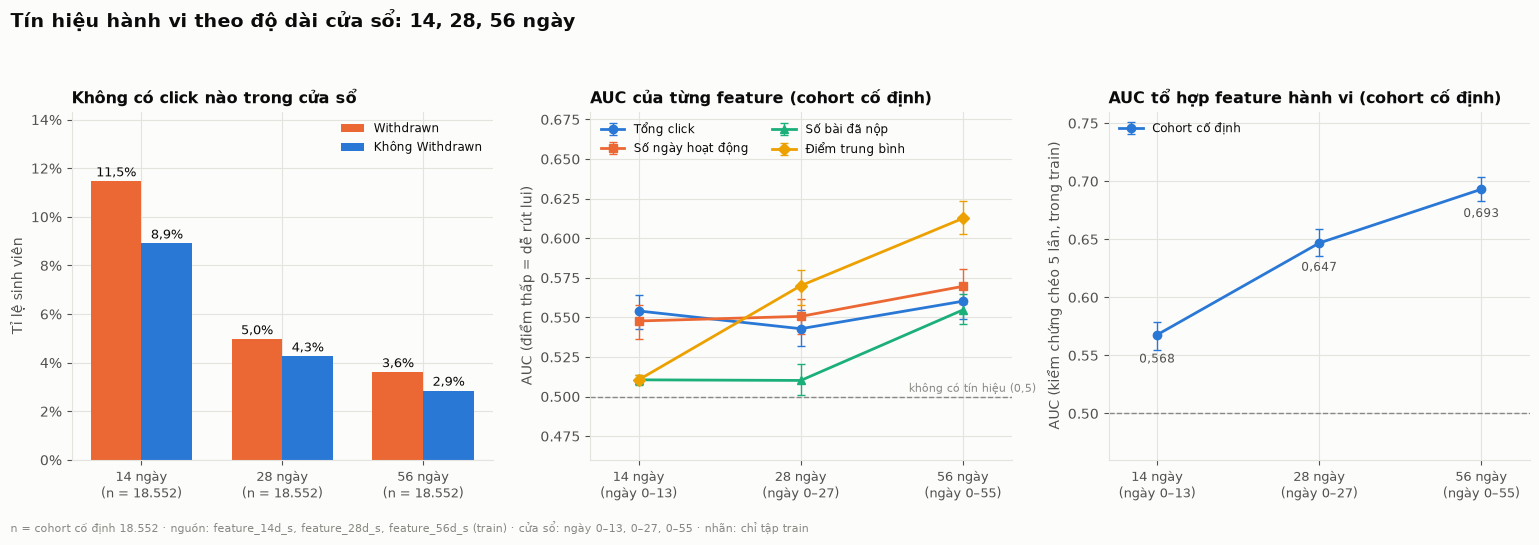

In [24]:
MANIFEST_W4 = []
def finish_w4(fig, cid, slug, title, source, n_text, window, data, top=0.93):
    fig.text(0.01, 0.006, f"n = {n_text} · nguồn: {source} · cửa sổ: {window} · nhãn: chỉ tập train",
             fontsize=8, color=MUTED, ha="left", va="bottom")
    fig.tight_layout(rect=(0, 0.04, 1, top))
    png, csv = EDA_DIR / f"{cid}_{slug}.png", EDA_DIR / f"{cid}_{slug}.csv"
    fig.savefig(png, dpi=150)
    data.to_csv(csv, index=False, encoding="utf-8-sig")
    MANIFEST_W4.append(dict(chart_id=cid, title=title, source=source, n=str(n_text), window=window,
                         label_used="có (chỉ train)", png=png.name, csv=csv.name))
    plt.show()

xs = np.arange(len(WINDOWS)); xl = [f"{w} ngày\n(ngày 0–{w-1})" for w in WINDOWS]
fig, axes = plt.subplots(1, 3, figsize=(15.5, 5.4))
fig.suptitle("Tín hiệu hành vi theo độ dài cửa sổ: 14, 28, 56 ngày", x=0.01, ha="left", fontsize=14, fontweight="bold")

# A. không có click nào, theo nhãn (cohort cố định)
ax = axes[0]
nw = [FIX[w].loc[FIX[w]["label_withdrawn"] == 1, "no_activity_flag"].mean() for w in WINDOWS]
nn = [FIX[w].loc[FIX[w]["label_withdrawn"] == 0, "no_activity_flag"].mean() for w in WINDOWS]
bw = 0.36
b1 = ax.bar(xs - bw/2, nw, bw, color=ORANGE, label="Withdrawn")
b2 = ax.bar(xs + bw/2, nn, bw, color=BLUE, label="Không Withdrawn")
for bars, vals in ((b1, nw), (b2, nn)):
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width()/2, v + 0.002, f"{v:.1%}".replace(".", ","), ha="center", fontsize=9, color=INK)
ax.set_xticks(xs); ax.set_xticklabels([f"{w} ngày\n(n = {fmt(len(FIX[w]))})" for w in WINDOWS], fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0)); ax.set_ylim(0, max(nw + nn) * 1.25)
ax.set_title("Không có click nào trong cửa sổ"); ax.set_ylabel("Tỉ lệ sinh viên")
ax.legend(loc="upper right", fontsize=8.5)

# B. AUC từng feature (cohort cố định)
ax = axes[1]
ax.axhline(0.5, color=MUTED, lw=1, ls="--"); ax.text(len(WINDOWS) - 0.55, 0.503, "không có tín hiệu (0,5)", fontsize=8, color=MUTED, ha="right")
sty = {"total_clicks": (BLUE, "o"), "active_days": (ORANGE, "s"), "n_assess_submitted": (AQUA, "^"), "avg_score": (YELLOW, "D")}
for col, label in UNI:
    s = sig[(sig["loai"] == "auc_tung_feature") & (sig["feature"] == col)].sort_values("cua_so")
    colr, mk = sty[col]
    ax.errorbar(xs, s["auc"], yerr=[s["auc"] - s["ci_lo"], s["ci_hi"] - s["auc"]], color=colr, marker=mk, ms=6, lw=2, capsize=3, elinewidth=1, label=label)
ax.set_xticks(xs); ax.set_xticklabels(xl, fontsize=9); ax.set_xlim(-0.3, len(WINDOWS) - 0.7)
ax.set_title("AUC của từng feature (cohort cố định)"); ax.set_ylabel("AUC (điểm thấp = dễ rút lui)")
ax.set_ylim(0.46, 0.68); ax.legend(loc="upper left", fontsize=8.5, ncol=2)

# C. AUC tổ hợp
ax = axes[2]
ax.axhline(0.5, color=MUTED, lw=1, ls="--")
for cohort, label, colr, mk, ls in ((("co_dinh", "Cohort cố định", BLUE, "o", "-"),) + (() if SAME else (("rieng", "Cohort riêng", GREY, "s", "--"),))):
    s = sig[(sig["loai"] == "auc_to_hop") & (sig["cohort"] == cohort)].sort_values("cua_so")
    ax.errorbar(xs, s["auc"], yerr=[s["auc"] - s["ci_lo"], s["ci_hi"] - s["auc"]], color=colr, marker=mk, ms=6, lw=2, ls=ls, capsize=3, elinewidth=1, label=label)
    for x, v in zip(xs, s["auc"]):
        ax.text(x, v + (-0.024 if cohort == "co_dinh" else 0.016), f"{v:.3f}".replace(".", ","), fontsize=8.5, color=INK2, ha="center")
ax.set_xticks(xs); ax.set_xticklabels(xl, fontsize=9); ax.set_xlim(-0.3, len(WINDOWS) - 0.7)
ax.set_title("AUC tổ hợp feature hành vi (cohort cố định)" if SAME else "AUC tổ hợp feature hành vi"); ax.set_ylabel("AUC (kiểm chứng chéo 5 lần, trong train)")
ax.set_ylim(0.46, 0.76); ax.legend(loc="upper left", fontsize=8.5)

plot_data = sig.drop(columns=[], errors="ignore")
finish_w4(fig, "w4_10", "window_signal", "Tín hiệu theo cửa sổ 14, 28, 56 ngày",
       "feature_14d_s, feature_28d_s, feature_56d_s (train)",
       f"cohort cố định {fmt(len(FIX[14]))}" + ("" if SAME else f"; riêng {fmt(len(OWN[14]))} / {fmt(len(OWN[28]))} / {fmt(len(OWN[56]))}"),
       "ngày 0–13, 0–27, 0–55", plot_data)

## 5. Tóm tắt tuần 4 và danh sách hình

In [25]:
manifest = pd.DataFrame(MANIFEST_W4)
manifest.to_csv(EDA_DIR / "eda_manifest_week4.csv", index=False, encoding="utf-8-sig")

def g(loai, cohort, w, feat=None):
    q = sig[(sig["loai"] == loai) & (sig["cohort"] == cohort) & (sig["cua_so"] == w)]
    if feat: q = q[q["feature"] == feat]
    return q.iloc[0]
L = ["# Tóm tắt EDA tuần 4 (Đạt)", "",
     "Biểu đồ 10: tín hiệu theo cửa sổ 14, 28, 56 ngày. Mọi phân tích có nhãn chỉ trên tập **train**.", "",
     "## Kiểm tra bảng 14 và 56 ngày", ""]
L += [f"- [{r.ket_qua}] {r.muc}" + (f" ({r.chi_tiet})" if r.chi_tiet else "") for r in checks_df.itertuples() if r.ket_qua != "ĐẠT"]
L.append(f"- [ĐẠT] {int((checks_df['ket_qua']=='ĐẠT').sum())} mục còn lại (xem `w4_window_checks.csv`).")
L += ["", "## Điểm chính", ""]
if SAME:
    L.append(f"- Cả ba bảng dùng cùng cohort cố định (còn đăng ký ngày 56): {fmt(len(keysets[56]))} lượt; train n = {fmt(len(FIX[14]))}, Withdrawn {FIX[14]['label_withdrawn'].mean():.1%}.")
else:
    L.append("- Cohort riêng (train): " + "; ".join(f"{w} ngày n = {fmt(len(OWN[w]))}, Withdrawn {OWN[w]['label_withdrawn'].mean():.1%}" for w in WINDOWS)
             + f". Cohort cố định (còn đăng ký ngày 56): n = {fmt(len(FIX[14]))}, Withdrawn {FIX[14]['label_withdrawn'].mean():.1%}.")
L.append("- Không có click nào (Withdrawn / không Withdrawn): " + "; ".join(
    f"{w} ngày {FIX[w].loc[FIX[w]['label_withdrawn']==1,'no_activity_flag'].mean():.1%} / {FIX[w].loc[FIX[w]['label_withdrawn']==0,'no_activity_flag'].mean():.1%}" for w in WINDOWS) + ".")
L.append("- AUC tổ hợp feature hành vi, cohort cố định: " + "; ".join(f"{w} ngày {g('auc_to_hop','co_dinh',w)['auc']:.3f}" for w in WINDOWS)
         + ("" if SAME else "; cohort riêng: " + "; ".join(f"{w} ngày {g('auc_to_hop','rieng',w)['auc']:.3f}" for w in WINDOWS)) + ".")
for col, label in UNI:
    L.append(f"- AUC {label.lower()} (cohort cố định): " + "; ".join(f"{w} ngày {g('auc_tung_feature','co_dinh',w,col)['auc']:.3f}" for w in WINDOWS) + ".")
gap = g('auc_to_hop','co_dinh',56)['auc'] - g('auc_to_hop','co_dinh',14)['auc']
got = g('auc_to_hop','co_dinh',28)['auc'] - g('auc_to_hop','co_dinh',14)['auc']
L.append(f"- Từ 14 lên 28 ngày AUC tổ hợp tăng {got:.3f}, chiếm {got/gap:.0%} mức tăng từ 14 lên 56 ngày ({gap:.3f}). Tín hiệu từng feature đều yếu (AUC gần 0,5 đến 0,6).")
if N_MAIN is not None:
    L.append(f"- Bảng 28 ngày độ nhạy có {fmt(len(FEAT[28]))} dòng, là tập con có chủ ý của cohort gốc {fmt(N_MAIN)} (bỏ {fmt(N_MAIN - len(FEAT[28]))} lượt rút trước ngày 56). Bộ này chỉ dùng để so sánh cửa sổ; kết quả mô hình chính dùng bộ gốc (feature_28d, split).")
else:
    L.append(f"- Bảng 28 ngày độ nhạy có {fmt(len(FEAT[28]))} dòng (cohort cố định, còn đăng ký ở đầu ngày 56).")
L += ["", "## Danh sách hình", ""]
L += [f"- `{r.png}` (n = {r.n}, nguồn: {r.source}, nhãn: {r.label_used})" for r in manifest.itertuples()]
(EDA_DIR / "eda_week4_summary.md").write_text("\n".join(L), encoding="utf-8")
print("\n".join(L))

# Tóm tắt EDA tuần 4 (Đạt)

Biểu đồ 10: tín hiệu theo cửa sổ 14, 28, 56 ngày. Mọi phân tích có nhãn chỉ trên tập **train**.

## Kiểm tra bảng 14 và 56 ngày

- [CẢNH BÁO] split_s.csv (độ nhạy) khác split.csv (gốc): chỉ dùng cho so sánh cửa sổ, không dùng cho kết quả chính (11.028 / 24.120 sinh viên chung khác tập)
- [ĐẠT] 27 mục còn lại (xem `w4_window_checks.csv`).

## Điểm chính

- Cả ba bảng dùng cùng cohort cố định (còn đăng ký ngày 56): 26.532 lượt; train n = 18.552, Withdrawn 15.5%.
- Không có click nào (Withdrawn / không Withdrawn): 14 ngày 11.5% / 8.9%; 28 ngày 5.0% / 4.3%; 56 ngày 3.6% / 2.9%.
- AUC tổ hợp feature hành vi, cohort cố định: 14 ngày 0.568; 28 ngày 0.647; 56 ngày 0.693.
- AUC tổng click (cohort cố định): 14 ngày 0.554; 28 ngày 0.543; 56 ngày 0.560.
- AUC số ngày hoạt động (cohort cố định): 14 ngày 0.548; 28 ngày 0.551; 56 ngày 0.570.
- AUC số bài đã nộp (cohort cố định): 14 ngày 0.511; 28 ngày 0.510; 56 ngày 0.555.
- AUC điểm trung bình (cohort cố định): 14 ngày 0.